# Whole-Tumour Segmentation in Multimodal 3D Brain MRI
**Medical Imaging_Assignment 2**

Zichen Zhao (25011189)

Goal: segment the whole tumour (every voxel with any tumour sub-region label) from a four-channel 3D MRI
volume with a lightweight 3D U-Net trained on patches, and compare uniform with tumour-aware patch sampling.
This is a learning exercise on a research reference segmentation, not a clinical tool.

## 0. Setup
### 0.1 Configuration
Every setting used below lives in this one dictionary. Trained runs are saved in `outputs/runs/` with the
settings they were trained with, and a saved run is reused only if those settings match exactly.

In [1]:
CONFIG = {
    # data
    "data_root": "Task01_BrainTumour",
    "split_file": "assignment2_split.csv",
    "cache_dir": "data/cache",           # cropped, normalised volumes (float16) and train/val labels
    "run_dir": "outputs/runs",           # checkpoints, training logs, per-case results
    # patches and model
    "patch_size": 64,                    # cubic training patch, voxels (= mm, the data are 1 mm isotropic)
    "batch_size": 4,
    "widths": [16, 32, 64, 128, 256],    # U-Net feature channels per level (4 downsamplings)
    # optimisation (identical for both samplers)
    "iterations": 3000,                  # training budget, in batches
    "lr": 1e-3,                          # AdamW peak learning rate
    "weight_decay": 1e-5,
    "warmup_iters": 100,                 # linear warm-up, then cosine decay to 0
    "eval_every": 300,                   # whole-volume validation every 300 iterations
    "n_monitor_train_cases": 15,         # fixed training cases evaluated like validation (overfitting check)
    "num_workers": 6,                    # DataLoader worker processes
    # sampling and augmentation
    "p_tumour": 0.5,                     # tumour-aware sampler: probability of centring a patch on tumour
    "rotate_deg": 10.0,                  # max axial rotation of the training augmentation
    # whole-volume inference
    "sw_overlap": 0.5,                   # sliding-window overlap (stride = patch * (1 - overlap))
    "sw_blend": "gaussian",              # blending weight of overlapping patches
    "sw_batch": 4,
    "threshold": 0.5,                    # probability threshold, fixed (not tuned)
    # seeds
    "train_seeds": [0, 1, 2],            # one run per sampler and seed
    "retrain": False,                    # True: ignore saved runs and train again
}

### 0.2 Imports, device and seeds

In [2]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import scipy
import torch
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

from helpers.volumes import (CHANNELS, LABEL_NAMES, header_facts, load_image, load_label, whole_tumour,
                             preprocess_all, load_cached, uncrop, resample, brain_box)
from helpers.patches import PatchDataset
from helpers.unet3d import UNet3D, count_parameters
from helpers.train import (set_seed, build_model, train_run, load_run, monitor_cases, initial_weights,
                           dice_bce_loss)
from helpers.inference import predict_volume, timed_predict, remove_small_components, components, window_starts
from helpers.metrics import case_metrics, bootstrap_ci, paired_bootstrap_diff
from helpers.paper_plot_style import (figsize, method_style, finish, label_lines, RED, PETROL, SLATE, OXBLOOD,
                                      GOLD, INK, MUTED, RULE, LABEL_PT, TICK_PT)
from helpers.plotting import (save_and_show, style_table, tint, plane, plane_index, show_plane, contour,
                              error_overlay, error_handles, crop_box, place_text, label_points, frame, display_centre, EDGE_LETTERS, PLANES, REF, PRED, ERR)

pd.set_option("display.width", 140)
DATA_ROOT = Path(CONFIG["data_root"])
CACHE_DIR = Path(CONFIG["cache_dir"])
RUN_DIR = Path(CONFIG["run_dir"])
TABLE_DIR = Path("outputs/tables")          # key tables, saved for the report
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Apple-silicon GPU (MPS) if present, else an NVIDIA GPU (CUDA), else the CPU.
DEVICE = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
set_seed(0)
print(f"device: {DEVICE} | torch {torch.__version__} | nibabel {nib.__version__} | numpy {np.__version__} "
      f"| scipy {scipy.__version__} | pandas {pd.__version__}")

device: mps | torch 2.14.1 | nibabel 5.4.2 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6


### 0.3 Verify the download
The check from the brief: 484 labelled cases, three splits, every listed file present.

In [3]:
split_df = pd.read_csv(CONFIG["split_file"])
assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}
for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


## A. Define the task and inspect the volumes
### A.1 The task
**Input.** One patient case: four co-registered 3D MRI volumes of the head (FLAIR, T1-weighted,
contrast-enhanced T1-weighted and T2-weighted), stored as one 4-channel NIfTI array of 240 × 240 × 155
voxels per channel. **Output.** A binary 3D mask on the same voxel grid: 1 where the model predicts whole
tumour, 0 elsewhere. The reference is the BraTS expert segmentation with every non-zero sub-region label
(oedema, non-enhancing tumour, enhancing tumour) mapped to 1. The original multi-class label files are left
untouched; the binary mask is derived when a label is loaded.

**Unit of analysis.** The patient case. A *voxel* is one 1 × 1 × 1 mm³ cell of the grid; a *slice* is one
2D plane of voxels (axial, coronal or sagittal); a *volume* is the full 3D array of one channel (or of the
label); a *patient case* is one patient's four volumes plus their reference label. In this dataset each
case is a different patient, so splitting by case is splitting by patient. Training draws 3D patches from
volumes, but every metric is computed per case on the whole volume and then summarised over cases.

**Intended technical use.** A research and learning pipeline that delineates the whole-tumour region and
measures its volume. The reference is a research segmentation, not pathology-confirmed tumour extent, so
agreement with it says nothing about clinical safety or suitability for treatment planning.

### A.2 Headers of three cases
We read three training cases (no test labels are opened here). The channel order comes from `dataset.json`;
the geometry comes from the NIfTI headers: the affine maps a voxel index (i, j, k) to scanner coordinates
in millimetres, and its orientation codes name the anatomical direction each array axis points to.

In [4]:
dataset_json = json.loads((DATA_ROOT / "dataset.json").read_text())
print("channel order (dataset.json 'modality'):", dataset_json["modality"])
print("label values (dataset.json 'labels'):   ", dataset_json["labels"])

by_id = split_df.set_index("case_id")
example_ids = split_df.loc[split_df["split"] == "train", "case_id"].iloc[:3].tolist()
rows = []
for cid in example_ids:
    h = header_facts(DATA_ROOT / by_id.loc[cid, "image_relpath"], DATA_ROOT / by_id.loc[cid, "label_relpath"])
    label_values = np.unique(np.asarray(nib.load(DATA_ROOT / by_id.loc[cid, "label_relpath"]).dataobj))
    rows.append({"case": cid, "image shape": h["image_shape"], "image dtype": h["image_dtype"],
                 "label shape": h["label_shape"], "label dtype": h["label_dtype"],
                 "orientation": h["orientation"], "voxel spacing (mm)": h["spacing_mm"],
                 "label values": label_values.tolist(), "image/label affine equal": h["same_affine"]})
display(pd.DataFrame(rows).set_index("case"))
print(f"affine of {example_ids[0]} (identical for its label):\n{h['affine']}")

channel order (dataset.json 'modality'): {'0': 'FLAIR', '1': 'T1w', '2': 't1gd', '3': 'T2w'}
label values (dataset.json 'labels'):    {'0': 'background', '1': 'edema', '2': 'non-enhancing tumor', '3': 'enhancing tumour'}


,image shape,image dtype,label shape,label dtype,orientation,voxel spacing (mm),label values,image/label affine equal
case,,,,,,,,
BRATS_001,"(240, 240, 155, 4)",float32,"(240, 240, 155)",uint8,RAS,"(1.0, 1.0, 1.0)","[0, 1, 2, 3]",True
BRATS_003,"(240, 240, 155, 4)",float32,"(240, 240, 155)",uint8,RAS,"(1.0, 1.0, 1.0)","[0, 1, 2, 3]",True
BRATS_004,"(240, 240, 155, 4)",float32,"(240, 240, 155)",uint8,RAS,"(1.0, 1.0, 1.0)","[0, 1, 2, 3]",True


affine of BRATS_001 (identical for its label):
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


All three cases share one geometry: 240 × 240 × 155 voxels of 1 mm, an identity affine, orientation code
RAS (array axis 0 points to the patient's Right, axis 1 to Anterior, axis 2 to Superior), and labels
{0, 1, 2, 3} = background, oedema, non-enhancing tumour, enhancing tumour. Section C checks this for all 484
cases.

### A.3 Four channels and the reference at one physical location
We pick the physical point at the centre of mass of the reference tumour of the first training case, convert
it to millimetres with the affine, and convert it back to a voxel index with the inverse affine. Because the
four channels are co-registered and share one affine, the same voxel index shows the same anatomy in every
channel. All panels use the display convention of `helpers/plotting.py`: radiological (patient's right on
the viewer's left), with orientation letters at the edges.

BRATS_001: tumour centre at voxel [157, 116, 67] = [157.0, 116.0, 67.0] mm (scanner RAS)


PASS A_views: 0 errors, 0 warnings, 17 taste notes -> figures/_preview/A_views.png
  [taste] crowded: 'P' and '(f) axial' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] contrast: 'R' is too light to read; use text_color()
  [taste] contrast: 'L' is too light to read; use text_color()
  [taste] contrast: 'A' is too light to read; use text_color()
  [taste] contrast: ... 13 more (see _audit/A_views.json)


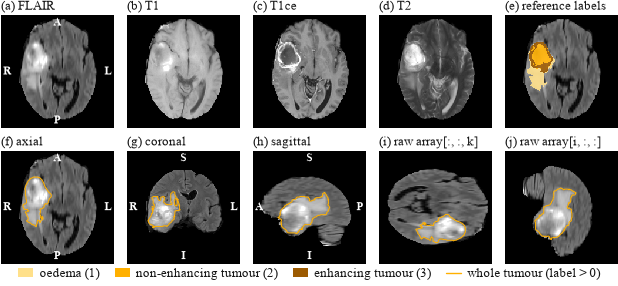

In [5]:
case_a = example_ids[0]
img_a, affine_a, spacing_a = load_image(DATA_ROOT / by_id.loc[case_a, "image_relpath"])
lab_a = load_label(DATA_ROOT / by_id.loc[case_a, "label_relpath"])
wt_a = whole_tumour(lab_a)
centre_vox = np.round(np.argwhere(wt_a).mean(axis=0)).astype(int)
centre_mm = nib.affines.apply_affine(affine_a, centre_vox)
centre_back = np.round(nib.affines.apply_affine(np.linalg.inv(affine_a), centre_mm)).astype(int)
assert (centre_back == centre_vox).all()
print(f"{case_a}: tumour centre at voxel {centre_vox.tolist()} = {np.round(centre_mm, 1).tolist()} mm (scanner RAS)")

brain_centre_a = np.round(np.argwhere(np.any(img_a != 0, axis=0)).mean(axis=0)).astype(int)
TILE = (192, 192)                                     # every panel shows the same 192 x 192 mm field of view


def tile(vol3d, which):
    """The plane through the tumour centre, laid out by the affine and cut to a fixed field around the brain."""
    return frame(plane(vol3d, which, plane_index(centre_vox, which)),
                 display_centre(brain_centre_a, which, vol3d.shape), TILE)


fig = plt.figure(figsize=figsize("full", aspect=0.45))
top, bottom, key = fig.subfigures(3, 1, height_ratios=[1, 1, 0.09], hspace=0.0)
axes_top, axes_bottom = top.subplots(1, 5), bottom.subplots(1, 5)
for c, name in enumerate(CHANNELS):
    show_plane(axes_top[c], tile(img_a[c], "axial"), letters=EDGE_LETTERS["axial"] if c == 0 else None)
    axes_top[c].set_title(f"({'abcde'[c]}) {name}", fontsize=TICK_PT)
# (e) the original multi-class reference: nested sub-regions in three lightness steps of the annotation gold
SUBREGION = {1: "#FFE08A", 2: "#FFB000", 3: "#9C5A00"}
show_plane(axes_top[4], tile(img_a[0], "axial"))
labels2d = tile(lab_a, "axial")
overlay = np.zeros(labels2d.shape + (4,))
for value, colour in SUBREGION.items():
    overlay[labels2d == value] = (*matplotlib.colors.to_rgb(colour), 0.9)
axes_top[4].imshow(overlay, origin="lower", interpolation="nearest")
axes_top[4].set_title("(e) reference labels", fontsize=TICK_PT)
for k, which in enumerate(PLANES):
    ax = axes_bottom[k]
    show_plane(ax, tile(img_a[0], which), letters=EDGE_LETTERS[which])
    contour(ax, tile(wt_a, which), REF)
    ax.set_title(f"({'fgh'[k]}) {which}", fontsize=TICK_PT)
# what a plot of raw array slices shows without the affine: imshow's default puts index [0, 0] at the top left
raw_axial = frame(img_a[0][:, :, centre_vox[2]], tuple(brain_centre_a[[0, 1]]), TILE)
raw_sag = frame(img_a[0][centre_vox[0]], tuple(brain_centre_a[[1, 2]]), TILE)
for ax, img2d, lab2d, title in [(axes_bottom[3], raw_axial, frame(wt_a[:, :, centre_vox[2]], tuple(brain_centre_a[[0, 1]]), TILE),
                                 "(i) raw array[:, :, k]"),
                                (axes_bottom[4], raw_sag, frame(wt_a[centre_vox[0]], tuple(brain_centre_a[[1, 2]]), TILE),
                                 "(j) raw array[i, :, :]")]:
    show_plane(ax, img2d, origin="upper")
    contour(ax, lab2d, REF, origin=None)
    ax.set_title(title, fontsize=TICK_PT)
key.legend(handles=[matplotlib.patches.Patch(facecolor=c, label=f"{LABEL_NAMES[v]} ({v})") for v, c in SUBREGION.items()]
           + [matplotlib.lines.Line2D([], [], color=REF, lw=1, label="whole tumour (label > 0)")],
           loc="center", ncol=4, frameon=False, handlelength=1.2, columnspacing=1.2)
save_and_show(fig, "A_views", width="full")
plt.close(fig)

### A.4 Why array index order is not enough
Panels (f)–(h) show the reference in the three anatomical planes, each cut through the same tumour centre and
laid out by the affine. Panels (i) and (j) plot the same data by raw array index, the way `imshow(array[:, :, k])`
would: the axial slice appears rotated by 90° with anterior pointing sideways, and the sagittal slice lies on
its side. Nothing in the array itself says which end of an axis is left or anterior: a file written in LPS
order holds the mirror image in exactly the same index layout. Only the affine (with its orientation codes)
ties indices to anatomy, so it must be read before any slice is shown, any flip is used for augmentation, or
any distance is measured in millimetres. Here the anatomy agrees with the header for the two directions that
anatomy can confirm: the cerebellum lies at low axis-1 indices (posterior) and the vertex at high axis-2
indices (superior). Left and right cannot be confirmed from a near-symmetric brain; we rely on the header.

## B. A reproducible case-level split
### B.1 Use the supplied split exactly
The split comes from `assignment2_split.csv` as supplied; nothing is re-drawn. Every unit in it is a whole
patient case, and patches are later drawn only from training cases, so no slice or patch of a validation or
test case can reach training.

In [6]:
SPLITS = ["train", "validation", "test"]
ids = {s: split_df.loc[split_df["split"] == s, "case_id"].tolist() for s in SPLITS}
train_ids, val_ids, test_ids = ids["train"], ids["validation"], ids["test"]
display(split_df.head(4))

,case_id,split,image_relpath,label_relpath
0,BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz
1,BRATS_002,test,imagesTr/BRATS_002.nii.gz,labelsTr/BRATS_002.nii.gz
2,BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz
3,BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz


### B.2 Files exist, identifiers are unique and the splits are disjoint

In [7]:
assert split_df["case_id"].is_unique
for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).is_file() and (DATA_ROOT / row.label_relpath).is_file()
    assert Path(row.image_relpath).name == Path(row.label_relpath).name == f"{row.case_id}.nii.gz"
for a in SPLITS:
    for b in SPLITS:
        if a < b:
            assert not set(ids[a]) & set(ids[b]), f"{a} and {b} share cases"
assert sum(len(v) for v in ids.values()) == 484
print("all 968 files exist; image and label names match the case id; the three splits share no case")

all 968 files exist; image and label names match the case id; the three splits share no case


### B.3 Case counts and reference tumour volume per split
Tumour volume = number of whole-tumour voxels × voxel volume (1 mm³) / 1000, in millilitres. Training and
validation volumes come from the preprocessing cache (section C). For the test split the label files are
opened here only to count voxels for this descriptive table; they are not used again until section F, and
no modelling choice depends on them.

In [8]:
metas = preprocess_all(split_df, DATA_ROOT, CACHE_DIR, min_size=CONFIG["patch_size"])   # section C explains it


def reference_volume_ml(case_id):
    if by_id.loc[case_id, "split"] == "test":
        lab = np.asarray(nib.load(DATA_ROOT / by_id.loc[case_id, "label_relpath"]).dataobj)
        zooms = nib.load(DATA_ROOT / by_id.loc[case_id, "label_relpath"]).header.get_zooms()
        return float((lab > 0).sum() * np.prod(zooms) / 1000)
    m = metas[case_id]
    return m["tumour_voxels"] * float(np.prod(m["spacing_mm"])) / 1000


split_df["tumour_ml"] = [reference_volume_ml(c) for c in split_df["case_id"]]
vol = split_df.groupby("split", sort=False)["tumour_ml"]
vol_table = pd.DataFrame({
    "cases": vol.size(), "mean (mL)": vol.mean(), "SD (mL)": vol.std(), "median (mL)": vol.median(),
    "IQR low": vol.quantile(0.25), "IQR high": vol.quantile(0.75), "min (mL)": vol.min(), "max (mL)": vol.max(),
}).loc[SPLITS]
display(style_table(vol_table, precision=1, caption="Reference whole-tumour volume per split"))
vol_table.to_csv(TABLE_DIR / "volumes_per_split.csv")
print("cases without any tumour voxel:", int((split_df["tumour_ml"] == 0).sum()))

,cases,mean (mL),SD (mL),median (mL),IQR low,IQR high,min (mL),max (mL)
split,,,,,,,,
train,338,103.0,57.0,95.5,60.0,143.9,8.5,265.3
validation,73,100.8,63.0,91.6,51.9,148.1,7.3,266.9
test,73,107.4,66.3,89.1,54.4,157.7,10.1,318.3


cases without any tumour voxel: 0


PASS B_volumes: 0 errors, 0 warnings, 0 taste notes -> figures/_preview/B_volumes.png


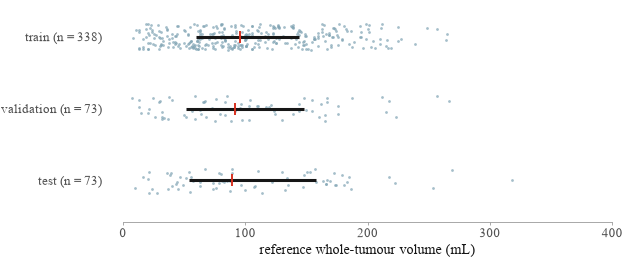

In [9]:
fig, ax = plt.subplots(figsize=figsize("column", aspect=0.42))
rng = np.random.default_rng(0)
for k, s in enumerate(SPLITS):
    v = split_df.loc[split_df["split"] == s, "tumour_ml"].to_numpy()
    ax.scatter(v, k + rng.uniform(-0.18, 0.18, len(v)), s=4, color=SLATE, alpha=0.7, linewidths=0)
    q1, med, q3 = np.percentile(v, [25, 50, 75])
    ax.plot([q1, q3], [k, k], color=INK, lw=2.2, solid_capstyle="butt")
    ax.plot([med], [k], marker="|", ms=9, mew=1.4, color=RED)
ax.set_yticks(range(3), [f"{s} (n = {len(ids[s])})" for s in SPLITS])
ax.set_ylim(2.5, -0.5)
ax.set_xlabel("reference whole-tumour volume (mL)")
finish(ax, categorical="y")
save_and_show(fig, "B_volumes", width="column")
plt.close(fig)

The three splits have similar tumour-volume distributions (overlapping interquartile ranges, similar
medians), so validation is a fair stand-in for the test split when we choose settings, and no split is
dominated by unusually small or large tumours.

## C. Preprocess MRI and labels safely
### C.1 Geometry of all four channels and the label, for every case
The four channels are stored as one 4D array, so they share a single affine by construction; the label is
a separate file and could differ. We read only the headers of all 484 image and label files (no voxel data,
so no label values are seen) and check that every case has the same grid.

In [10]:
geo = pd.DataFrame([{**header_facts(DATA_ROOT / r.image_relpath, DATA_ROOT / r.label_relpath), "case_id": r.case_id}
                    for r in split_df.itertuples()])
geo["affine_is_identity"] = [np.allclose(a, np.eye(4)) for a in geo["affine"]]
checks = {
    "image shape": geo["image_shape"].astype(str).value_counts().to_dict(),
    "label shape": geo["label_shape"].astype(str).value_counts().to_dict(),
    "image orientation": geo["orientation"].value_counts().to_dict(),
    "label orientation": geo["label_orientation"].value_counts().to_dict(),
    "image spacing (mm)": geo["spacing_mm"].astype(str).value_counts().to_dict(),
    "label spacing (mm)": geo["label_spacing_mm"].astype(str).value_counts().to_dict(),
    "image affine == label affine": geo["same_affine"].value_counts().to_dict(),
    "affine is identity": geo["affine_is_identity"].value_counts().to_dict(),
}
display(pd.Series(checks, name="value: number of cases").to_frame())
assert geo["same_affine"].all() and geo["label_shape"].nunique() == 1 and geo["spacing_mm"].nunique() == 1

,value: number of cases
image shape,"{'(240, 240, 155, 4)': 484}"
label shape,"{'(240, 240, 155)': 484}"
image orientation,{'RAS': 484}
label orientation,{'RAS': 484}
image spacing (mm),"{'(1.0, 1.0, 1.0)': 484}"
label spacing (mm),"{'(1.0, 1.0, 1.0)': 484}"
image affine == label affine,{True: 484}
affine is identity,{True: 484}


Every case has the same grid: 240 × 240 × 155 voxels of 1 × 1 × 1 mm, RAS orientation, and an image affine
equal to its label affine. **No resampling is needed.** The target grid is therefore the native grid itself
(1 mm isotropic, RAS+, 240 × 240 × 155); the only spatial operations are a reorientation to RAS+ (a no-op
here, kept so the code is safe for other data), cropping to the brain, and padding, none of which
interpolates.

### C.2 Linear interpolation for MRI, nearest neighbour for labels
Interpolation still happens in training: the rotation augmentation resamples every patch. To show why labels
need nearest-neighbour interpolation, we resample the label of one case two ways, once by rotating it 7° (as
the augmentation does) and once to a hypothetical 1.5 mm grid. Linear interpolation of a label invents values
between classes (for example 1.5, half oedema and half non-enhancing tumour), which are not valid labels; nearest
neighbour only copies existing labels.

In [11]:
from scipy import ndimage

rows = []
for name, fn in [("rotate 7° (augmentation)", lambda v, o: ndimage.rotate(v, 7, axes=(0, 1), reshape=False, order=o)),
                 ("resample to 1.5 mm", lambda v, o: resample(v, spacing_a, (1.5, 1.5, 1.5), order=o))]:
    for order, method in [(1, "linear"), (0, "nearest neighbour")]:
        out = fn(lab_a.astype(np.float32), order)
        values = np.unique(out)
        valid = np.isin(values, [0, 1, 2, 3]).all()
        invalid = values[~np.isin(values, [0, 1, 2, 3])]
        rows.append({"operation": name, "interpolation": method, "distinct values": len(values),
                     "invalid values (examples)": np.round(invalid[np.linspace(0, len(invalid) - 1, 4).astype(int)], 3).tolist()
                     if len(invalid) else [], "only valid labels {0,1,2,3}": bool(valid)})
display(pd.DataFrame(rows))
img_rot = ndimage.rotate(img_a[0], 7, axes=(0, 1), reshape=False, order=1)
print(f"MRI after linear rotation: intensities stay within the original range "
      f"[{img_a[0].min():.0f}, {img_a[0].max():.0f}] -> [{img_rot.min():.0f}, {img_rot.max():.0f}]")

,operation,interpolation,distinct values,invalid values (examples),"only valid labels {0,1,2,3}"
0,rotate 7° (augmentation),linear,19191,"[0.0, 0.6980000138282776, 2.114000082015991, 3.0]",False
1,rotate 7° (augmentation),nearest neighbour,4,[],True
2,resample to 1.5 mm,linear,2582,"[0.0010000000474974513, 0.9269999861717224, 2....",False
3,resample to 1.5 mm,nearest neighbour,4,[],True


MRI after linear rotation: intensities stay within the original range [0, 1829] -> [0, 1820]


### C.3 Normalise each channel from its brain voxels
MRI intensities have no physical unit and differ between scanners and sessions, so each channel of each case
is z-scored with the mean and SD of its own non-zero (brain) voxels. The zero background, about 83% of each
volume, would otherwise pull the mean towards 0 and shrink the SD, and its share depends on head size rather
than tissue. Background stays exactly 0 after normalisation. The statistics come from the case itself, so no
information flows between cases or splits. The cache was filled in B.3 with `preprocess_all`.

In [12]:
stat_rows = []
for c, name in enumerate(CHANNELS):
    s = pd.DataFrame([m["channel_stats"][c] for m in metas.values()])
    stat_rows.append({"channel": name, "raw mean (median over cases)": s["raw_mean"].median(),
                      "raw SD (median over cases)": s["raw_sd"].median(),
                      "normalised mean (mean over cases)": s["norm_mean"].mean(),
                      "normalised SD (mean over cases)": s["norm_sd"].mean(),
                      "largest |normalised mean|": s["norm_mean"].abs().max(),
                      "normalised SD range": f"{s['norm_sd'].min():.4f}–{s['norm_sd'].max():.4f}"})
norm_table = pd.DataFrame(stat_rows).set_index("channel")
background = 1 - np.array([m["brain_voxels"] / np.prod(m["full_shape"]) for m in metas.values()])
print(f"background (zero in every channel) share of the full volume: mean {background.mean():.1%}, "
      f"range {background.min():.1%}–{background.max():.1%}")
display(style_table(norm_table, precision=3, caption="Brain-voxel statistics before and after z-scoring, 484 cases"))

# the cached float16 arrays give the same answer (checks the cache, not just the stored statistics)
img_c = np.asarray(load_cached(case_a, CACHE_DIR, with_label=False)[0], dtype=np.float32)
raw_a = img_a[(slice(None),) + tuple(slice(a, b) for a, b in metas[case_a]["box"])]
for c, name in enumerate(CHANNELS):
    brain = raw_a[c] != 0
    print(f"{case_a} {name:5s} from the cache: brain mean {img_c[c][brain].mean():+.4f}, SD {img_c[c][brain].std():.4f}, "
          f"background still exactly 0: {bool((img_c[c][~brain] == 0).all())}")

background (zero in every channel) share of the full volume: mean 83.9%, range 79.2%–87.6%


,raw mean (median over cases),raw SD (median over cases),normalised mean (mean over cases),normalised SD (mean over cases),largest |normalised mean|,normalised SD range
channel,,,,,,
FLAIR,516.178,176.789,-0.000,1.000,0.000,1.0000–1.0000
T1,695.806,156.516,0.000,1.000,0.000,1.0000–1.0000
T1ce,650.236,156.681,-0.000,1.000,0.000,1.0000–1.0000
T2,501.832,188.943,-0.000,1.000,0.000,1.0000–1.0000


BRATS_001 FLAIR from the cache: brain mean +0.0000, SD 1.0000, background still exactly 0: True
BRATS_001 T1    from the cache: brain mean -0.0000, SD 1.0000, background still exactly 0: True
BRATS_001 T1ce  from the cache: brain mean -0.0000, SD 1.0000, background still exactly 0: True
BRATS_001 T2    from the cache: brain mean -0.0000, SD 1.0000, background still exactly 0: True


### C.4 Crop, pad and augment
**Crop and pad.** Every case is cropped to the bounding box of its brain (voxels non-zero in any channel) and
padded with zeros at the far end of any axis shorter than the patch. The crop removes about two thirds of each
volume, all of it empty background, so uniform patches are drawn from the head rather than from air. The crop
box is stored, and predictions are put back into the full 240 × 240 × 155 grid before any metric is computed.
Every reference tumour voxel lies inside its brain box (asserted during preprocessing).

In [13]:
shapes = pd.DataFrame([m["cropped_shape"] for m in metas.values()], columns=["x (R-L)", "y (A-P)", "z (S-I)"])
display(shapes.describe().loc[["min", "50%", "max"]].rename(index={"50%": "median"}).astype(int))
n_padded = sum(any(s < CONFIG["patch_size"] for s in m["cropped_shape"]) for m in metas.values())
print(f"cases needing padding to {CONFIG['patch_size']} voxels: {n_padded}; "
      f"mean fraction of the full volume kept: {np.mean([np.prod(m['cropped_shape']) / np.prod(m['full_shape']) for m in metas.values()]):.2f}")

,x (R-L),y (A-P),z (S-I)
min,122,144,119
median,138,169,138
max,160,187,149


cases needing padding to 64 voxels: 0; mean fraction of the full volume kept: 0.36


**Patch size.** The patch must be small enough that a uniformly drawn patch can miss the tumour, otherwise the two
samplers of section D would see the same thing. We draw 25 uniform patches from each of 80 random training cases for
five patch sizes and count how many contain tumour. (This uses training labels only.)

In [14]:
rng = np.random.default_rng(0)
probe_cases = rng.choice(train_ids, 80, replace=False)
probe_labels = {c: np.asarray(load_cached(c, CACHE_DIR)[1]) > 0 for c in probe_cases}
rows = []
for size in [32, 48, 64, 80, 96]:
    has, frac = [], []
    for lab in probe_labels.values():
        for _ in range(25):
            s0 = [rng.integers(0, max(d - size, 0) + 1) for d in lab.shape]
            patch = lab[s0[0]:s0[0] + size, s0[1]:s0[1] + size, s0[2]:s0[2] + size]
            has.append(patch.any())
            frac.append(patch.mean())
    rows.append({"patch size": f"{size}³", "uniform patches containing tumour": np.mean(has),
                 "mean tumour share of patch voxels": np.mean(frac)})
display(pd.DataFrame(rows).set_index("patch size").round(3))
del probe_labels
diam = (6 * split_df.loc[split_df["split"] == "train", "tumour_ml"] * 1000 / np.pi) ** (1 / 3)
print(f"training tumours: diameter of a sphere of equal volume, median {diam.median():.0f} mm "
      f"(IQR {diam.quantile(0.25):.0f}–{diam.quantile(0.75):.0f} mm)")

,uniform patches containing tumour,mean tumour share of patch voxels
patch size,,
32³,0.306,0.050
48³,0.550,0.068
64³,0.780,0.066
80³,0.938,0.068
96³,0.992,0.067


training tumours: diameter of a sphere of equal volume, median 57 mm (IQR 49–65 mm)


With 96³ patches almost every uniform patch already contains tumour, so we use 64³ patches (about four in five
contain tumour), which leaves the tumour-aware sampler room to change what the network sees while keeping enough
context for a tumour whose equal-volume sphere is typically 5–6 cm across.

**Augmentation (training patches only).** Each transform imitates a variation real scans have, and none
changes what the tissue is:
- *left-right flip* (p = 0.5): gliomas occur in either hemisphere and the brain is close to mirror symmetric,
  so a mirrored brain is still a plausible brain. No anterior-posterior or superior-inferior flips, which would
  create anatomy that does not exist;
- *axial rotation* (p = 0.5, ±10°): residual head tilt; linear interpolation for MRI, nearest neighbour for the
  label (C.2);
- *intensity scale and shift* per channel (× U(0.9, 1.1), + U(−0.1, 0.1) SD, brain voxels only): scanner gain
  and contrast differences left after z-scoring.

Validation and test volumes are never augmented. Below, the same training patch (same case, same position) is
shown without and with augmentation. The example is chosen by rule: the first uniform-sampler patch whose draw
includes both a flip and a rotation and whose middle slice shows tumour and the edge of the brain, so that the
transforms are visible.

patch 52 of BRATS_191: left-right flip, rotation -4.6°, FLAIR × 1.059 -0.094 SD, T1ce × 0.953 -0.093 SD


PASS C_augmentation: 0 errors, 0 warnings, 11 taste notes -> figures/_preview/C_augmentation.png
  [taste] crowded: 'P' and '(d) augmented, FLAIR' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] crowded: 'P' and '(e) augmented, T1ce' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] contrast: 'R' is too light to read; use text_color()
  [taste] contrast: 'L' is too light to read; use text_color()
  [taste] contrast: 'A' is too light to read; use text_color()
  [taste] contrast: ... 6 more (see _audit/C_augmentation.json)


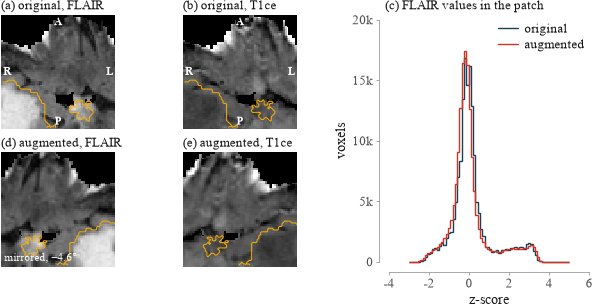

augmented mask values: [0.0, 1.0] | mask voxels before/after: 25602 25569


In [15]:
aug_ds = PatchDataset(train_ids, CACHE_DIR, CONFIG["patch_size"], 1000, sampler="uniform", seed=0, augment=True,
                      rotate_deg=CONFIG["rotate_deg"])
plain_ds = PatchDataset(train_ids, CACHE_DIR, CONFIG["patch_size"], 1000, sampler="uniform", seed=0, augment=False)


def augmentation_draw(i):
    """The augmentation parameters drawn for patch i (same order as in PatchDataset.__getitem__)."""
    rng = aug_ds.draw(i)[3]
    flip, rotate = rng.random() < 0.5, rng.random() < 0.5
    angle = rng.uniform(-aug_ds.rotate_deg, aug_ds.rotate_deg)
    scale, shift = rng.uniform(0.9, 1.1, size=4), rng.uniform(-0.1, 0.1, size=4)
    return flip, rotate, angle, scale, shift


def shows_anatomy(i):
    """Rule for the example: tumour in the middle slice and the brain edge in view, so flip and rotation are visible."""
    item = plain_ds[i]
    mid_slice = item["image"][0, :, :, CONFIG["patch_size"] // 2]
    brain_share = float((mid_slice != 0).float().mean())
    return item["mask"][0, :, :, CONFIG["patch_size"] // 2].sum() > 300 and 0.5 < brain_share < 0.9


idx = next(i for i in range(1000) if all(augmentation_draw(i)[:2]) and shows_anatomy(i))
before, after = plain_ds[idx], aug_ds[idx]
flip, rotate, angle, scale, shift = augmentation_draw(idx)
print(f"patch {idx} of {before['case_id']}: left-right flip, rotation {angle:+.1f}°, FLAIR × {scale[0]:.3f} "
      f"{shift[0]:+.3f} SD, T1ce × {scale[2]:.3f} {shift[2]:+.3f} SD")
mid = CONFIG["patch_size"] // 2
fig, axes = plt.subplot_mosaic([["a", "b", "c"], ["d", "e", "c"]], figsize=figsize("full", aspect=0.5),
                               width_ratios=[1, 1, 1.2])
for r, (item, name) in enumerate([(before, "original"), (after, "augmented")]):
    for c, ch in enumerate([0, 2]):
        key = "ab"[c] if r == 0 else "de"[c]
        ax = axes[key]
        show_plane(ax, plane(item["image"][ch].numpy(), "axial", mid), window=(-2.5, 4.0),
                   letters=EDGE_LETTERS["axial"] if r == 0 else None)
        contour(ax, plane(item["mask"][0].numpy(), "axial", mid), REF)
        ax.set_title(f"({key}) {name}, {CHANNELS[ch]}", fontsize=TICK_PT)
axes["d"].text(0.03, 0.03, f"mirrored, {angle:+.1f}°".replace("-", "−"), transform=axes["d"].transAxes,
               color="white", fontsize=TICK_PT - 1, ha="left", va="bottom")
ax = axes["c"]
for item, color, name in [(before, PETROL, "original"), (after, RED, "augmented")]:
    v = item["image"][0].numpy()
    ax.hist(v[v != 0], bins=70, range=(-3, 5), color=color, histtype="step", lw=1.0, label=name)
ax.set_title("(c) FLAIR values in the patch", fontsize=TICK_PT)
ax.set_xlabel("z-score")
ax.set_ylabel("voxels")
finish(ax, y="k")
ax.legend(handles=[matplotlib.lines.Line2D([], [], color=PETROL, lw=1, label="original"),
                   matplotlib.lines.Line2D([], [], color=RED, lw=1, label="augmented")], loc="upper right")
save_and_show(fig, "C_augmentation", width="full")
plt.close(fig)
mask_values = set(np.unique(after["mask"].numpy()).tolist())
assert mask_values <= {0.0, 1.0}
print("augmented mask values:", sorted(mask_values), "| mask voxels before/after:",
      int(before["mask"].sum()), int(after["mask"].sum()))

## D. Patch-based volumetric training
### D.1 Dataset and DataLoader
`PatchDataset` (in `helpers/patches.py`) returns one random training patch per index: the image as a
[C, D, H, W] = [4, 64, 64, 64] float tensor (channels FLAIR, T1, T1ce, T2; spatial axes R, A, S) and the binary
whole-tumour mask as [1, 64, 64, 64]. Patch i is drawn with its own random generator seeded by (seed, i), so the
patch sequence is fixed by the seed alone. We print and check one batch of the uniform sampler.

In [16]:
from torch.utils.data import DataLoader

P, B = CONFIG["patch_size"], CONFIG["batch_size"]
probe = DataLoader(PatchDataset(train_ids, CACHE_DIR, P, n_samples=B, sampler="uniform", seed=0, augment=True,
                                rotate_deg=CONFIG["rotate_deg"]), batch_size=B, shuffle=False, num_workers=0)
batch = next(iter(probe))
x, y = batch["image"], batch["mask"]
print(f"image batch: shape {tuple(x.shape)} = [batch, C, D, H, W], dtype {x.dtype}, "
      f"range [{x.min():.2f}, {x.max():.2f}]")
print(f"mask batch:  shape {tuple(y.shape)} = [batch, 1, D, H, W], dtype {y.dtype}, values {y.unique().tolist()}")
print("cases:", batch["case_id"], "| tumour voxels per patch:", y.sum(dim=(1, 2, 3, 4)).int().tolist())
assert x.shape == (B, 4, P, P, P) and y.shape == (B, 1, P, P, P)
assert set(y.unique().tolist()) <= {0.0, 1.0} and torch.isfinite(x).all()
assert set(batch["case_id"]) <= set(train_ids)                         # only training cases reach training

image batch: shape (4, 4, 64, 64, 64) = [batch, C, D, H, W], dtype torch.float32, range [-5.68, 11.47]


mask batch:  shape (4, 1, 64, 64, 64) = [batch, 1, D, H, W], dtype torch.float32, values [0.0, 1.0]
cases: ['BRATS_413', 'BRATS_245', 'BRATS_475', 'BRATS_237'] | tumour voxels per patch: [0, 651, 358, 40866]


### D.2 A lightweight 3D U-Net
Five levels with 16, 32, 64, 128 and 256 feature channels: each level has two 3×3×3 convolutions with instance
normalisation and leaky ReLU; strided convolutions halve the resolution four times (64 → 4 voxels), transposed
convolutions double it again, and skip connections carry the encoder features of each level to the decoder. A
final 1×1×1 convolution gives one logit per voxel. Instance normalisation replaces batch normalisation because a
batch holds only four patches. The network is fully convolutional, so the same weights apply to a whole volume.

In [17]:
model_probe = build_model(CONFIG)
with torch.no_grad():
    out = model_probe(torch.zeros(1, 4, P, P, P))
n_params = count_parameters(model_probe)
print(f"input channels: 4 (FLAIR, T1, T1ce, T2) | output channels: 1 (whole-tumour logit) | "
      f"patch size: {P}×{P}×{P} voxels = {P}×{P}×{P} mm")
print(f"trainable parameters: {n_params:,} ({n_params / 1e6:.2f} M) | output shape for one patch: {tuple(out.shape)}")
print("feature channels per level:", CONFIG["widths"], "| resolution per level:",
      [P // 2 ** k for k in range(len(CONFIG["widths"]))])

input channels: 4 (FLAIR, T1, T1ce, T2) | output channels: 1 (whole-tumour logit) | patch size: 64×64×64 voxels = 64×64×64 mm
trainable parameters: 5,647,681 (5.65 M) | output shape for one patch: (1, 1, 64, 64, 64)
feature channels per level: [16, 32, 64, 128, 256] | resolution per level: [64, 32, 16, 8, 4]


### D.3 Training with uniform random patches
Settings shared by every run (from `CONFIG`):
- **loss** soft Dice + binary cross-entropy on the batch (Dice counters the class imbalance, tumour being
  about 7% of brain voxels; BCE gives every voxel a gradient);
- **optimiser** AdamW, peak learning rate 1e-3, weight decay 1e-5, 100 warm-up iterations then cosine decay to 0;
- **budget** 3,000 iterations of 4 patches = 12,000 patches, about 36 per training case;
- **seed** 0 (weights initialisation, patch stream, augmentation draws);
- **checkpoint** every 300 iterations the model predicts all 73 validation cases and 15 fixed training cases
  with the full sliding-window pipeline; the checkpoint with the highest validation Dice is kept.

Training takes about an hour per run on an Apple M4 Max GPU, so finished runs are loaded from
`outputs/runs/` when their saved configuration matches `CONFIG` exactly.

In [18]:
monitor_ids = monitor_cases(train_ids, CONFIG["n_monitor_train_cases"])
SAMPLERS = ["uniform", "tumour"]
run_dirs = {}
for seed in CONFIG["train_seeds"]:
    run_dirs[("uniform", seed)] = train_run(CONFIG, "uniform", seed, train_ids, val_ids, monitor_ids, DEVICE,
                                            retrain=CONFIG["retrain"])

uniform_seed0: reusing the saved run (configuration matches)
uniform_seed1: reusing the saved run (configuration matches)
uniform_seed2: reusing the saved run (configuration matches)


### D.4 Training with tumour-aware patches
The tumour-aware sampler centres a patch on a randomly chosen reference tumour voxel with probability 0.5 and
otherwise draws it uniformly. Everything else is held fixed: the run loads the same initial weights file as the
uniform run of its seed, uses the same patch-stream seed (so the same cases are visited in the same order), the
same loss, optimiser, schedule and 3,000-iteration budget.

In [19]:
for seed in CONFIG["train_seeds"]:
    run_dirs[("tumour", seed)] = train_run(CONFIG, "tumour", seed, train_ids, val_ids, monitor_ids, DEVICE,
                                           retrain=CONFIG["retrain"])

runs = {k: load_run(d, CONFIG, which="best", device=DEVICE) for k, d in run_dirs.items()}
for seed in CONFIG["train_seeds"]:
    u, t = runs[("uniform", seed)][3], runs[("tumour", seed)][3]
    assert u["init_weights"] == t["init_weights"], "the two samplers must start from the same weights"
    cu = json.loads((run_dirs[("uniform", seed)] / "config.json").read_text())
    ct = json.loads((run_dirs[("tumour", seed)] / "config.json").read_text())
    assert {k for k in cu if cu[k] != ct[k]} == {"sampler"}, "only the sampler may differ"
print("each pair of runs shares its initial weights file and every setting except the sampler")

rows = []
for (sampler, seed), (_, hist, iters, summ) in runs.items():
    rows.append({"sampler": sampler, "seed": seed, "patches": len(iters) * B,
                 "patches containing tumour": iters["tumour_patches"].sum() / (len(iters) * B),
                 "patches centred on tumour": iters["aimed_patches"].sum() / (len(iters) * B),
                 "mean tumour fraction of patch voxels": iters["tumour_voxel_frac"].mean(),
                 "training minutes": summ["minutes"], "best iteration": summ["best_iteration"]})
sampling_table = pd.DataFrame(rows).set_index(["sampler", "seed"])
display(style_table(sampling_table, precision=3, caption="What each sampler showed the network (all training batches)"))
sampling_table.to_csv(TABLE_DIR / "sampling.csv")
display(style_table(sampling_table.groupby(level="sampler").agg(["mean", "std"]).loc[SAMPLERS].drop(columns=["patches"]),
                    precision=3, caption="The same, mean and SD over seeds"))

tumour_seed0: reusing the saved run (configuration matches)
tumour_seed1: reusing the saved run (configuration matches)
tumour_seed2: reusing the saved run (configuration matches)


each pair of runs shares its initial weights file and every setting except the sampler


### D.5 Learning curves
Training and validation loss are computed the same way, on whole volumes with the sliding-window pipeline
(training: the 15 fixed training cases; validation: all 73 cases), so their gap measures overfitting. Panel (c)
shows the loss on the training patches themselves (moving average over 100 iterations); its level depends on
what the sampler shows the network, so it is not comparable with (a). With more than one seed, lines are means and
bands span the lowest to the highest seed.

PASS D_curves: 0 errors, 0 warnings, 4 taste notes -> figures/_preview/D_curves.png
  [taste] crowded: '3' and 'Dice, whole volumes' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] band: uncertainty band alpha 1.00; keep bands quiet (~0.15)
  [taste] band: uncertainty band alpha 1.00; keep bands quiet (~0.15)
  [taste] band: uncertainty band alpha 1.00; keep bands quiet (~0.15)


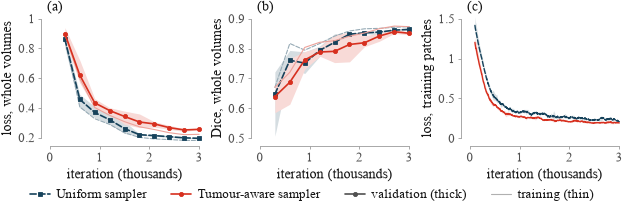

In [20]:
def seed_stack(sampler, column, frame="history"):
    """Matrix [seed, step] of one logged column (history: every 300 iterations; iterations: every iteration)."""
    idx = 1 if frame == "history" else 2
    return np.stack([runs[(sampler, sd)][idx][column].to_numpy() for sd in CONFIG["train_seeds"]])


fig = plt.figure(figsize=figsize("full", aspect=0.33))
panel_fig, key_fig = fig.subfigures(2, 1, height_ratios=[1, 0.1], hspace=0.0)
axes = panel_fig.subplots(1, 3)
hist_it = runs[("uniform", CONFIG["train_seeds"][0])][1]["iteration"].to_numpy() / 1000
iter_it = runs[("uniform", CONFIG["train_seeds"][0])][2]["iteration"].to_numpy() / 1000
for sampler in SAMPLERS:
    st = method_style(sampler)
    ls = st.get("linestyle", "-")
    for ax, (val_col, train_col) in zip(axes[:2], [("val_loss", "train_loss"), ("val_dice", "train_dice")]):
        v, t = seed_stack(sampler, val_col), seed_stack(sampler, train_col)
        if len(CONFIG["train_seeds"]) > 1:
            ax.fill_between(hist_it, v.min(0), v.max(0), color=tint(st["color"], 0.18), lw=0)
        ax.plot(hist_it, t.mean(0), color=tint(st["color"], 0.45), ls=ls, lw=0.8)
        ax.plot(hist_it, v.mean(0), color=st["color"], ls=ls, marker=st["marker"], ms=3, label=st["label"])
    window = 100                                              # moving average, defined from iteration 100 on
    patch = pd.DataFrame(seed_stack(sampler, "loss", "iterations").T).rolling(window).mean().to_numpy().T[:, window - 1:]
    if len(CONFIG["train_seeds"]) > 1:
        axes[2].fill_between(iter_it[window - 1:], patch.min(0), patch.max(0), color=tint(st["color"], 0.18), lw=0)
    axes[2].plot(iter_it[window - 1:], patch.mean(0), color=st["color"], ls=ls, lw=1.0, label=st["label"])
axes[0].set_ylabel("loss, whole volumes")
axes[1].set_ylabel("Dice, whole volumes")
axes[2].set_ylabel("loss, training patches")
for ax, tag in zip(axes, "abc"):
    ax.set_xlabel("iteration (thousands)")
    ax.set_title(f"({tag})", loc="left")
    ax.set_xlim(0, 3.05)
    finish(ax)
us, ts = method_style("uniform"), method_style("tumour")
key_fig.legend(handles=[
    matplotlib.lines.Line2D([], [], color=us["color"], ls=us.get("linestyle", "-"), marker=us["marker"], ms=3, label=us["label"]),
    matplotlib.lines.Line2D([], [], color=ts["color"], ls=ts.get("linestyle", "-"), marker=ts["marker"], ms=3, label=ts["label"]),
    matplotlib.lines.Line2D([], [], color=MUTED, marker="o", ms=3, label="validation (thick)"),
    matplotlib.lines.Line2D([], [], color=tint(MUTED, 0.45), lw=0.8, label="training (thin)")],
    loc="center", ncol=4, frameon=False)
save_and_show(fig, "D_curves", width="full")
plt.close(fig)
curve_table = pd.concat({s: pd.concat([runs[(s, sd)][1].set_index("iteration")[["train_loss", "val_loss", "train_dice", "val_dice"]]
                                         for sd in CONFIG["train_seeds"]]).groupby(level=0).agg(["mean", "std"])
                         for s in SAMPLERS}, axis=1)
display(style_table(curve_table, precision=3, caption=f"Whole-volume loss and Dice, mean and SD over {len(CONFIG['train_seeds'])} seeds"))

**Reading the curves.** Both samplers learn steadily and neither overfits within the budget. Averaged over three
seeds, validation Dice passes 0.80 by iteration 1,500 with uniform sampling (0.821) and by 2,100 with tumour-aware
sampling (0.819). For the uniform runs, training and validation curves stay close to the end (whole-volume loss
0.179 vs 0.195, Dice 0.873 vs 0.864 at iteration 3,000), and validation Dice is still rising over the last 600
iterations (0.855 to 0.864) while the learning rate decays to zero, which suggests mild underfitting: a longer
budget would probably help a little. The tumour-aware runs end with a wider gap (Dice 0.873 vs 0.851) and vary much
more between seeds in mid-training (validation Dice SD 0.052 at iteration 1,800, against 0.005 for uniform), which
points to a less stable optimisation rather than to memorising training cases. Their patch loss in (c) is lower, but
that reflects patches with more tumour (which shrinks the soft-Dice term), not a more accurate model; whole-volume
loss (a) is the comparable measure, and there uniform sampling is lower throughout.

## E. Controlled sampling comparison
### E.1 What is held fixed
The two conditions differ in one setting only, the patch sampler (asserted in D.4). Everything below is evaluated
on the 73 validation cases with the best-validation-Dice checkpoint of each run and the full pipeline: sliding
window, threshold 0.5, prediction placed back into the full grid, no postprocessing.

In [21]:
fixed = json.loads((run_dirs[("uniform", CONFIG["train_seeds"][0])] / "config.json").read_text())
display(pd.Series({k: fixed[k] for k in ["patch_size", "batch_size", "iterations", "widths", "lr", "weight_decay",
                                         "warmup_iters", "rotate_deg", "sw_overlap", "sw_blend", "threshold"]}
                  | {"loss": "soft Dice + BCE", "optimiser": "AdamW", "train / validation cases":
                     f"{len(fixed['train_ids'])} / {len(fixed['val_ids'])}"}, name="shared by both samplers").to_frame())

,shared by both samplers
patch_size,64
batch_size,4
iterations,3000
widths,"[16, 32, 64, 128, 256]"
lr,0.001
weight_decay,0.00001
warmup_iters,100
rotate_deg,10.0
sw_overlap,0.5
sw_blend,gaussian


### E.2 Validation Dice, sensitivity and false-positive volume

In [22]:
from helpers.evaluate import load_references, predict_split, score_split, summarise, full_mask

val_refs = load_references(val_ids, split_df, DATA_ROOT)
val_masks, val_scores = {}, {}
for key, (model, *_rest) in runs.items():
    val_masks[key], _, _ = predict_split(model, val_ids, CONFIG, DEVICE)
    val_scores[key] = score_split(val_masks[key], val_refs, CONFIG)

rows = []
for (sampler, seed), df in val_scores.items():
    rows.append({"sampler": sampler, "seed": seed, "Dice mean": df["dice"].mean(), "Dice median": df["dice"].median(),
                 "sensitivity mean": df["sensitivity"].mean(), "precision mean": df["precision"].mean(),
                 "FP volume mean (mL)": df["fp_ml"].mean(), "FP volume median (mL)": df["fp_ml"].median(),
                 "FN volume mean (mL)": df["fn_ml"].mean(), "HD95 median (mm)": df["hd95_mm"].median(),
                 "empty predictions": int(df["empty_pred"].sum())})
val_table = pd.DataFrame(rows).set_index(["sampler", "seed"])
display(style_table(val_table, precision=3, caption="Validation, 73 cases, best checkpoint of each run"))
val_table.to_csv(TABLE_DIR / "validation_per_run.csv")

if len(CONFIG["train_seeds"]) > 1:
    agg = val_table.groupby(level="sampler").agg(["mean", "std"])
    agg = agg.loc[SAMPLERS, [c for c in agg.columns if c[0] != "empty predictions"]]
    display(style_table(agg, precision=3, caption=f"Validation, mean and SD over {len(CONFIG['train_seeds'])} seeds"))

# paired differences per case: tumour-aware − uniform, each case's metric averaged over the seeds of a sampler
mean_over_seeds = {s: pd.concat([val_scores[(s, sd)] for sd in CONFIG["train_seeds"]]).groupby(level=0).mean().loc[val_ids]
                   for s in SAMPLERS}
diff_rows = []
for metric, name in [("dice", "Dice"), ("sensitivity", "sensitivity"), ("precision", "precision"),
                     ("fp_ml", "FP volume (mL)"), ("fn_ml", "FN volume (mL)"), ("hd95_mm", "HD95 (mm)")]:
    d, lo, hi = paired_bootstrap_diff(mean_over_seeds["tumour"][metric], mean_over_seeds["uniform"][metric])
    diff_rows.append({"metric": name, "uniform": mean_over_seeds["uniform"][metric].mean(),
                      "tumour-aware": mean_over_seeds["tumour"][metric].mean(),
                      "tumour-aware − uniform": d, "95% CI low": lo, "95% CI high": hi})
diff_table = pd.DataFrame(diff_rows).set_index("metric")
display(style_table(diff_table, precision=3,
                    caption=f"Paired difference over the 73 validation cases, case metrics averaged over "
                            f"{len(CONFIG['train_seeds'])} seed(s) (percentile bootstrap, 2,000 resamples)"))
diff_table.to_csv(TABLE_DIR / "validation_paired_difference.csv")

,uniform,tumour-aware,tumour-aware − uniform,95% CI low,95% CI high
metric,,,,,
Dice,0.865,0.858,-0.006,-0.015,0.003
sensitivity,0.878,0.907,0.029,0.021,0.038
precision,0.868,0.831,-0.038,-0.052,-0.025
FP volume (mL),11.930,17.245,5.315,3.257,7.998
FN volume (mL),12.053,8.842,-3.211,-4.240,-2.271
HD95 (mm),16.821,23.219,6.398,3.705,9.515


PASS E_comparison: 0 errors, 0 warnings, 1 taste notes -> figures/_preview/E_comparison.png
  [taste] crowded: 'tumour-aware' and 'false-positive volume (mL)' (different panels) nearly touch; add wspace/hspace or use fewer ticks


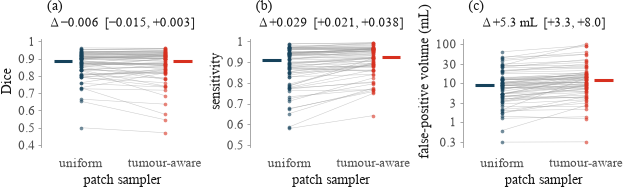

In [23]:
def per_case(sampler, metric):
    """Per validation case, the metric averaged over the seeds of one sampler."""
    return pd.concat([val_scores[(sampler, sd)][metric] for sd in CONFIG["train_seeds"]], axis=1).mean(axis=1).loc[val_ids]


fig, axes = plt.subplots(1, 3, figsize=figsize("full", aspect=0.31))
panels = [("dice", "Dice", False, "{:+.3f}"), ("sensitivity", "sensitivity", False, "{:+.3f}"),
          ("fp_ml", "false-positive volume (mL)", True, "{:+.1f} mL")]
for ax, (metric, name, log, fmt), tag in zip(axes, panels, "abc"):
    u, t = per_case("uniform", metric), per_case("tumour", metric)
    d, lo, hi = paired_bootstrap_diff(t, u)
    if log:
        u, t = u.clip(lower=0.3), t.clip(lower=0.3)
    for cid in val_ids:                                                   # one grey line per case
        ax.plot([0, 1], [u[cid], t[cid]], color=RULE, lw=0.35, alpha=0.55, zorder=1)
    for x0, side, v, key in [(0, -1, u, "uniform"), (1, 1, t, "tumour")]:
        st = method_style(key)
        ax.scatter(np.full(len(v), x0), v, s=7, color=st["color"], alpha=0.6, linewidths=0, zorder=2)
        ax.plot([x0 + side * 0.1, x0 + side * 0.32], [np.median(v)] * 2, color=st["color"], lw=2.2, zorder=3,
                solid_capstyle="butt")                                   # median, beside the dots
    ax.set_xticks([0, 1], ["uniform", "tumour-aware"])
    ax.set_xlim(-0.4, 1.4)
    ax.set_ylabel(name)
    ax.set_title(f"({tag})", loc="left")
    if log:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(matplotlib.ticker.FixedLocator([0.3, 1, 3, 10, 30, 100]))
        ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    finish(ax, categorical="x")
    ax.set_xlabel("patch sampler")
    lo_y, hi_y = ax.get_ylim()                                           # headroom for the difference label
    top = hi_y * 4 if log else hi_y + 0.22 * (hi_y - lo_y)
    ax.set_ylim(lo_y, top)
    ax.spines["left"].set_bounds(lo_y, hi_y)
    ax.text(0.5, 0.985, ("Δ " + fmt.format(d) + f"  [{fmt.format(lo).split()[0]}, {fmt.format(hi).split()[0]}]").replace("-", "−"),
            transform=ax.transAxes, ha="center", va="top", fontsize=TICK_PT, color=INK)
save_and_show(fig, "E_comparison", width="full")
plt.close(fig)

**Mechanism.** Tumour-aware sampling changes what the network is trained on: 89.0% instead of 78.1% of patches
contain tumour, and tumour makes up 15.7% instead of 7.1% of patch voxels (D.4). The network learns this inflated
prior, so at inference, where tumour is again a small share of the brain box, it calls tumour more readily. Over three
seeds this shows exactly as expected: sensitivity rises (+0.029, 95% CI +0.021 to +0.038) and missed tumour volume
falls (−3.2 mL), but false-positive volume rises more (+5.3 mL, +3.3 to +8.0), precision drops (−0.038) and mean HD95
grows (+6.4 mm), so Dice does not improve (−0.006, −0.015 to +0.003). Oversampling pays off when uniform patches
rarely contain the target; here, with whole tumours of median 90 mL and 64³ patches, 78% of uniform patches already
contain tumour, so the benefit is small and the prior shift dominates.

### E.3 Select the final configuration on validation evidence
Rule, fixed before looking at the numbers: the sampler with the higher mean validation Dice (averaged over seeds)
is chosen; within it, the seed whose checkpoint has the highest validation Dice becomes the final model.

In [24]:
mean_val_dice = {s: np.mean([val_scores[(s, sd)]["dice"].mean() for sd in CONFIG["train_seeds"]]) for s in SAMPLERS}
FINAL_SAMPLER = max(mean_val_dice, key=mean_val_dice.get)
FINAL_SEED = max(CONFIG["train_seeds"], key=lambda sd: val_scores[(FINAL_SAMPLER, sd)]["dice"].mean())
final_model = runs[(FINAL_SAMPLER, FINAL_SEED)][0]
print("mean validation Dice:", {s: round(v, 4) for s, v in mean_val_dice.items()})
print(f"final configuration: {FINAL_SAMPLER} sampler, seed {FINAL_SEED}, checkpoint at iteration "
      f"{runs[(FINAL_SAMPLER, FINAL_SEED)][3]['best_iteration']}")

mean validation Dice: {'uniform': np.float64(0.8645), 'tumour': np.float64(0.8585)}
final configuration: uniform sampler, seed 2, checkpoint at iteration 3000


**Too much oversampling.** If nearly every patch is centred on tumour, the network rarely sees the hard negatives
that live far from the tumour: bright FLAIR from other causes, vessels, the edges of the brain and the posterior
fossa. Its learned tumour prior is then far above the true one, and on whole volumes it produces false positives
in exactly those regions. The usual remedy is a moderate rate (nnU-Net uses one in three) and checking
false-positive volume, not only sensitivity, on validation.

## F. Reconstruct and evaluate full volumes
### F.1 Overlapping sliding-window inference
The cropped volume is covered by 64³ windows placed every 32 voxels along each axis (stride 32, 50% overlap); the
last window on each axis is shifted back to end at the border, so every voxel is covered. Each window's sigmoid
probabilities are multiplied by a 3D Gaussian weight (σ = 64/8 = 8 voxels, centred on the window) and summed;
dividing by the summed weights gives the blended probability. Only then is the 0.5 threshold applied. The Gaussian
lowers the vote of voxels near a window border, where the network saw the least context. The cropped prediction is
then written back into the full 240 × 240 × 155 grid (zeros outside the brain box).

In [25]:
example = val_ids[0]
shape_ex = metas[example]["cache_shape"]
stride = int(round(P * (1 - CONFIG["sw_overlap"])))
starts = [window_starts(s, P, stride) for s in shape_ex]
print(f"patch {P}³, stride {stride}, overlap {CONFIG['sw_overlap']:.0%}, blending: {CONFIG['sw_blend']} (σ = {P / 8:.0f} voxels)")
print(f"{example}: cropped volume {shape_ex} -> window starts per axis {starts} -> "
      f"{np.prod([len(s) for s in starts])} windows")
prob_ex, weight_ex, corners_ex = predict_volume(final_model, np.asarray(load_cached(example, CACHE_DIR, with_label=False)[0], dtype=np.float32),
                                                P, overlap=CONFIG["sw_overlap"], blend=CONFIG["sw_blend"],
                                                batch_size=CONFIG["sw_batch"], device=DEVICE, return_weight=True)
full_ex = uncrop((prob_ex >= CONFIG["threshold"]).astype(np.uint8), metas[example])
print(f"blended probability range [{prob_ex.min():.3f}, {prob_ex.max():.3f}]; every voxel covered: {bool((weight_ex > 0).all())}; "
      f"full-grid prediction shape {full_ex.shape}")

patch 64³, stride 32, overlap 50%, blending: gaussian (σ = 8 voxels)
BRATS_006: cropped volume [146, 175, 146] -> window starts per axis [[0, 32, 64, 82], [0, 32, 64, 96, 111], [0, 32, 64, 82]] -> 80 windows


blended probability range [0.000, 1.000]; every voxel covered: True; full-grid prediction shape (240, 240, 155)


### F.2 Choose the connected-component rule on validation
A whole tumour is one or a few large connected regions, while many false positives of a patch-based model are
small isolated islands (bright vessels or artefacts in FLAIR, edges of the brain), far from the tumour. The rule
is therefore: **remove every 26-connected component smaller than k mL** of the predicted mask. Unlike "keep only
the largest component", it keeps a second large lesion of a multifocal tumour. k is chosen on the validation
split only, by mean Dice (ties broken by smaller k), from a grid fixed in advance; "largest component only" is
shown for comparison.

In [26]:
val_final = val_masks[(FINAL_SAMPLER, FINAL_SEED)]
pp_rows = []
for k_ml in [0, 0.1, 0.25, 0.5, 1, 2, 5]:
    df = score_split(val_final, val_refs, CONFIG, min_voxels=int(round(k_ml * 1000)))
    pp_rows.append({"rule": f"remove components < {k_ml} mL" if k_ml else "none", "k (mL)": k_ml,
                    "Dice mean": df["dice"].mean(), "HD95 median (mm)": df["hd95_mm"].median(),
                    "HD95 mean (mm)": df["hd95_mm"].mean(), "FP volume mean (mL)": df["fp_ml"].mean(),
                    "sensitivity mean": df["sensitivity"].mean(), "empty predictions": int(df["empty_pred"].sum())})
from helpers.inference import keep_largest_component
lcc = pd.DataFrame([{"case_id": c, **case_metrics(keep_largest_component(full_mask(m, c, CONFIG)), *val_refs[c])}
                    for c, m in val_final.items()]).set_index("case_id")
pp_rows.append({"rule": "largest component only", "k (mL)": np.nan, "Dice mean": lcc["dice"].mean(),
                "HD95 median (mm)": lcc["hd95_mm"].median(), "HD95 mean (mm)": lcc["hd95_mm"].mean(),
                "FP volume mean (mL)": lcc["fp_ml"].mean(), "sensitivity mean": lcc["sensitivity"].mean(),
                "empty predictions": int(lcc["empty_pred"].sum())})
pp_table = pd.DataFrame(pp_rows).set_index("rule")
display(style_table(pp_table, precision=3, caption="Connected-component rules on validation (73 cases), final model"))
pp_table.to_csv(TABLE_DIR / "postprocessing_rules.csv")
candidates = pp_table.dropna(subset=["k (mL)"])
K_ML = float(candidates.loc[candidates["Dice mean"] == candidates["Dice mean"].max(), "k (mL)"].min())
MIN_VOXELS = int(round(K_ML * 1000))
print(f"chosen on validation: remove components smaller than {K_ML} mL ({MIN_VOXELS} voxels at 1 mm³)")

,k (mL),Dice mean,HD95 median (mm),HD95 mean (mm),FP volume mean (mL),sensitivity mean,empty predictions
rule,,,,,,,
none,0.000,0.870,5.916,14.470,11.124,0.882,0
remove components < 0.1 mL,0.100,0.870,5.916,14.533,11.078,0.881,0
remove components < 0.25 mL,0.250,0.870,5.916,14.457,11.043,0.881,0
remove components < 0.5 mL,0.500,0.870,5.916,14.460,10.999,0.881,0
remove components < 1 mL,1.000,0.871,5.916,13.959,10.919,0.881,0
remove components < 2 mL,2.000,0.872,5.916,11.844,10.771,0.881,0
remove components < 5 mL,5.000,0.873,5.099,10.759,10.542,0.880,0
largest component only,–,0.864,5.000,9.245,9.136,0.859,0


chosen on validation: remove components smaller than 5.0 mL (5000 voxels at 1 mm³)


On validation, mean Dice rises steadily with k and is highest at k = 5 mL, the largest value of the grid (0.870 to
0.873), which also lowers the mean HD95 from 14.5 to 10.8 mm. Because the optimum lies at the edge of the grid, a
larger k might score higher still; we did not extend the grid after seeing the test results. "Largest component only"
gives a lower validation Dice (0.864) and lower sensitivity, because it deletes true second lesions.

### F.3 Test evaluation
The test labels are read for the first time here, after the sampler, checkpoint, threshold, overlap and
postprocessing rule have all been fixed on validation. HD95 is undefined for an empty prediction; such cases are
counted and left out of the HD95 summary.

For transparency: an earlier execution of this notebook with seed 0 alone evaluated its selected model (uniform, seed
0) on the test split. The two extra seeds had been planned before that run, and no setting was changed in response
to its test results.

In [27]:
test_refs = load_references(test_ids, split_df, DATA_ROOT)
test_masks, test_seconds, _ = predict_split(final_model, test_ids, CONFIG, DEVICE)
test_raw = score_split(test_masks, test_refs, CONFIG, min_voxels=0)
test_pp = score_split(test_masks, test_refs, CONFIG, min_voxels=MIN_VOXELS)

cols = ["dice", "iou", "sensitivity", "hd95_mm"]
summary = pd.concat({"before postprocessing": summarise(test_raw, cols), "after postprocessing": summarise(test_pp, cols)}, axis=1)
ci = pd.DataFrame({(stage, m): [f"[{lo:.3f}, {hi:.3f}]" for lo, hi in [bootstrap_ci(df[m])]]
                   for stage, df in [("before postprocessing", test_raw), ("after postprocessing", test_pp)] for m in cols},
                  index=["95% CI of mean"])
display(style_table(summary, precision=3, caption=f"Test split, {len(test_ids)} cases, final model ({FINAL_SAMPLER}, seed {FINAL_SEED})"))
display(ci)
summary.to_csv(TABLE_DIR / "test_summary.csv")
ci.to_csv(TABLE_DIR / "test_ci.csv")
pd.concat({"before": test_raw, "after": test_pp}, axis=1).to_csv(TABLE_DIR / "test_cases.csv")
print(f"inference time: {np.mean(list(test_seconds.values())):.2f} s per case (mean)")
case_table = pd.concat({"before": test_raw[cols], "after": test_pp[cols]}, axis=1).round(3)
display(case_table)

before postprocessing                                                 after postprocessing                                  \
                                dice             iou     sensitivity         hd95_mm                 dice             iou     sensitivity   
95% CI of mean        [0.866, 0.898]  [0.771, 0.819]  [0.859, 0.902]  [5.709, 9.030]       [0.869, 0.899]  [0.776, 0.822]  [0.857, 0.901]   

                                
                       hd95_mm  
95% CI of mean  [5.849, 9.953]

inference time: 0.89 s per case (mean)


before                             after                           
            dice    iou sensitivity hd95_mm   dice    iou sensitivity hd95_mm
case_id                                                                      
BRATS_002  0.885  0.794       0.983   4.000  0.886  0.795       0.983   4.000
BRATS_012  0.910  0.835       0.909   7.550  0.910  0.835       0.909   7.550
BRATS_016  0.895  0.810       0.957   4.123  0.895  0.810       0.957   4.123
BRATS_033  0.947  0.899       0.965   2.000  0.947  0.899       0.965   2.000
BRATS_039  0.831  0.712       0.721   5.000  0.831  0.712       0.721   5.000
...          ...    ...         ...     ...    ...    ...         ...     ...
BRATS_462  0.819  0.693       0.734   8.062  0.822  0.698       0.734   8.062
BRATS_466  0.884  0.791       0.988   2.449  0.884  0.791       0.988   2.449
BRATS_467  0.937  0.881       0.891   2.236  0.938  0.883       0.891   2.236
BRATS_481  0.848  0.736       0.896  37.229  0.857  0.750       0.896  37.537
BRATS_482  0.784  0.644       0.675  15.906  0.784  0.644       0.675  20.640

[73 rows x 8 columns]

In [28]:
d, lo, hi = paired_bootstrap_diff(test_pp["dice"], test_raw["dice"])
dh, loh, hih = paired_bootstrap_diff(test_pp["hd95_mm"], test_raw["hd95_mm"])
changed = (test_pp["pred_ml"] != test_raw["pred_ml"]).sum()
print(f"postprocessing changed the prediction of {changed} of {len(test_ids)} test cases")
print(f"Dice after − before: {d:+.4f} (95% CI {lo:+.4f} to {hi:+.4f}); HD95 after − before: {dh:+.2f} mm "
      f"(95% CI {loh:+.2f} to {hih:+.2f})")

# what the rule removed: components smaller than k, and how much reference tumour they contained
removed = []
for cid in test_ids:
    raw = full_mask(test_masks[cid], cid, CONFIG, 0).astype(bool)
    ref = test_refs[cid][0].astype(bool)
    labels, sizes = components(raw)
    for j, size in enumerate(sizes, start=1):
        if size < MIN_VOXELS:
            tp = int((ref[labels == j]).sum())
            removed.append({"case_id": cid, "voxels": int(size), "tp_voxels": tp})
removed = pd.DataFrame(removed)
print(f"removed {len(removed)} components in {removed['case_id'].nunique()} cases; {int((removed['tp_voxels'] > 0).sum())} "
      f"of them overlapped the reference; together they held {removed['tp_voxels'].sum():,} true-positive and "
      f"{(removed['voxels'] - removed['tp_voxels']).sum():,} false-positive voxels")
worse_hd = (test_pp["hd95_mm"] - test_raw["hd95_mm"]).sort_values(ascending=False).head(3)
print("largest HD95 increases (mm):", {c: round(v, 1) for c, v in worse_hd.items()})
cid = worse_hd.index[0]
lost = removed[(removed["case_id"] == cid) & (removed["tp_voxels"] > 0)]
print(f"{cid}: Dice {test_raw.loc[cid, 'dice']:.3f} -> {test_pp.loc[cid, 'dice']:.3f}, HD95 {test_raw.loc[cid, 'hd95_mm']:.1f} -> "
      f"{test_pp.loc[cid, 'hd95_mm']:.1f} mm; the rule removed {len(lost)} components that held reference tumour "
      f"({lost['voxels'].sum() / 1000:.1f} mL in total, {lost['tp_voxels'].sum() / 1000:.1f} mL of it true positive)")

postprocessing changed the prediction of 59 of 73 test cases
Dice after − before: +0.0023 (95% CI +0.0004 to +0.0052); HD95 after − before: +0.47 mm (95% CI -0.62 to +1.87)


removed 310 components in 59 cases; 67 of them overlapped the reference; together they held 7,248 true-positive and 28,067 false-positive voxels
largest HD95 increases (mm): {'BRATS_253': 37.5, 'BRATS_246': 13.7, 'BRATS_341': 9.4}
BRATS_253: Dice 0.902 -> 0.903, HD95 19.4 -> 56.9 mm; the rule removed 2 components that held reference tumour (0.2 mL in total, 0.1 mL of it true positive)


**Postprocessing on the test set.** The rule chosen on validation raises test Dice very slightly (+0.0023, 95% CI
+0.0004 to +0.0052) but does not carry its validation HD95 gain over: HD95 changes by +0.47 mm (−0.62 to +1.87). It is
kept, as fixed in advance, and reported as close to neutral. The components it removed show the trade-off: 67 of the
310 contained reference tumour, and together the removed components held 7,248 true-positive voxels alongside 28,067
false-positive ones. The case whose HD95 rose most, BRATS_253, shows the mechanism: the model touched three small
satellite lesions only with tiny fragments (0.2 mL in total, half of it true positive), the rule deleted them, and
the lesions became entirely missed. Dice barely changed (0.902 to 0.903), but HD95 rose from 19.4 to 56.9 mm,
because the lesions lie 60 to 82 mm from the main tumour (G.2). A size rule tuned on Dice favours large-lesion
overlap over detecting small lesions.

### F.4 Tumour volume in millilitres
Volume = voxel count × voxel volume. The voxel volume comes from the header spacing (1 × 1 × 1 mm = 1 mm³), so
1,000 voxels = 1 mL. Volume error = predicted − reference volume, absolute and as a percentage of the reference.

,reference (mL),predicted (mL),error (mL),|error| (mL),error (%),|error| (%)
case_id,,,,,,
BRATS_002,63.06,76.97,13.91,13.91,22.05,22.05
BRATS_012,21.61,21.59,-0.02,0.02,-0.12,0.12
BRATS_016,82.73,94.10,11.38,11.38,13.75,13.75
BRATS_033,114.02,118.28,4.26,4.26,3.74,3.74
BRATS_039,37.01,27.19,-9.82,9.82,-26.54,26.54
...,...,...,...,...,...,...
BRATS_462,38.31,30.14,-8.18,8.18,-21.34,21.34
BRATS_466,16.75,20.69,3.94,3.94,23.53,23.53
BRATS_467,157.75,142.03,-15.72,15.72,-9.97,9.97


,reference (mL),predicted (mL),error (mL),|error| (mL),error (%),|error| (%)
mean,107.39,103.17,-4.22,12.72,-1.11,12.88
SD,66.28,61.55,17.49,12.63,16.49,10.25
median,89.11,92.03,-1.49,7.99,-1.08,10.13


volume error: bias -1.1%, 95% limits of agreement -33.4% to +31.2%


PASS F_volumes: 0 errors, 0 warnings, 0 taste notes -> figures/_preview/F_volumes.png


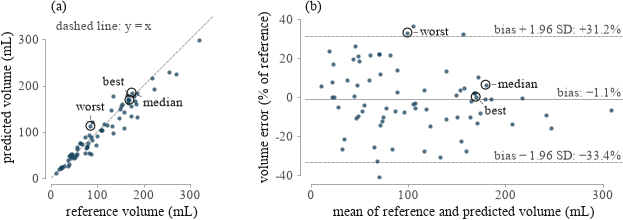

In [29]:
vol_cols = ["ref_ml", "pred_ml", "vol_err_ml", "abs_vol_err_ml", "vol_err_pct", "abs_vol_err_pct"]
volume_table = test_pp[vol_cols].rename(columns={"ref_ml": "reference (mL)", "pred_ml": "predicted (mL)",
                                                 "vol_err_ml": "error (mL)", "abs_vol_err_ml": "|error| (mL)",
                                                 "vol_err_pct": "error (%)", "abs_vol_err_pct": "|error| (%)"})
display(volume_table.round(2))
volume_summary = volume_table.agg(["mean", "std", "median"]).rename(index={"std": "SD"})
display(style_table(volume_summary, precision=2, caption="Volume error over the test cases (after postprocessing)"))
volume_summary.to_csv(TABLE_DIR / "volume_summary.csv")

# the best, median and worst test cases by final Dice (used again in section G)
order = test_pp["dice"].sort_values()
picked = {"best": order.index[-1], "median": order.index[len(order) // 2], "worst": order.index[0]}
bias, sd_err = test_pp["vol_err_pct"].mean(), test_pp["vol_err_pct"].std()
print(f"volume error: bias {bias:+.1f}%, 95% limits of agreement {bias - 1.96 * sd_err:+.1f}% to {bias + 1.96 * sd_err:+.1f}%")

color = method_style(FINAL_SAMPLER)["color"]
fig, axes = plt.subplots(1, 2, figsize=figsize("full", aspect=0.36), width_ratios=[1, 1.35])
ax = axes[0]
lim = 50 * np.ceil(max(test_pp["ref_ml"].max(), test_pp["pred_ml"].max()) / 50)
ax.plot([0, lim], [0, lim], color=RULE, lw=0.6, ls="--", zorder=1)
ax.scatter(test_pp["ref_ml"], test_pp["pred_ml"], s=9, color=color, alpha=0.75, linewidths=0, zorder=2)
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("reference volume (mL)")
ax.set_ylabel("predicted volume (mL)")
ax.set_title("(a)", loc="left")
finish(ax, snap=False)
ax.text(0.03, 0.97, "dashed line: y = x", transform=ax.transAxes, ha="left", va="top",
        fontsize=TICK_PT, color=MUTED)
ax = axes[1]
mean_v = (test_pp["ref_ml"] + test_pp["pred_ml"]) / 2
ax.scatter(mean_v, test_pp["vol_err_pct"], s=9, color=color, alpha=0.75, linewidths=0, zorder=2)
ax.set_xlabel("mean of reference and predicted volume (mL)")
ax.set_ylabel("volume error (% of reference)")
ax.set_title("(b)", loc="left")
finish(ax)
ax.set_xlim(right=max(ax.get_xlim()[1], mean_v.max() * 1.04))     # keep edge points off the frame
for y, ls, lab in [(bias, "-", "bias"), (bias + 1.96 * sd_err, "--", "bias + 1.96 SD"), (bias - 1.96 * sd_err, "--", "bias − 1.96 SD")]:
    ax.axhline(y, color=RULE, lw=0.6, ls=ls, zorder=1)
    ax.text(0.995, y, f"{lab}: {y:+.1f}%".replace("-", "−"), transform=ax.get_yaxis_transform(), color=MUTED,
            fontsize=TICK_PT, va="bottom", ha="right")
for ax_, xs, ys in [(axes[0], test_pp["ref_ml"], test_pp["pred_ml"]), (axes[1], mean_v, test_pp["vol_err_pct"])]:
    for name, cid in picked.items():                                 # ring and name the cases of Figure G
        ax_.scatter([xs[cid]], [ys[cid]], s=40, facecolors="none", edgecolors=INK, linewidths=0.8, zorder=3)
    label_points(ax_, [((xs[cid], ys[cid]), name) for name, cid in picked.items()])
save_and_show(fig, "F_volumes", width="full")
plt.close(fig)

**Reading the volumes.** Predicted and reference volumes agree closely over the whole range (panel a). The mean
signed error is −1.1% (no systematic over- or under-segmentation), but single cases spread widely: 95% of errors
fall between −33.4% and +31.2%, and the median absolute error is 10.1%. The worst case by Dice is also one of the
largest overestimates (+33.2%).

## G. Three-plane error analysis and limitations
### G.1 Best, median and worst test cases
Cases are picked by rule from the final (postprocessed) test Dice: the highest, the median (the 37th of 73) and
the lowest. Columns (a)–(c) show the axial, coronal and sagittal planes through the centre of mass of the union of
reference and prediction, on FLAIR, with true-positive, false-positive and false-negative voxels coloured. Every
panel of a plane type has the same field of view and scale. Column (d) projects the errors of *all* axial slices
onto one image, so an error outside the three planes is still visible.

In [30]:
print("cases picked in F.4:", picked)
final_pred = {c: full_mask(test_masks[c], c, CONFIG, MIN_VOXELS).astype(bool) for c in picked.values()}


def flair_full(case_id):
    return load_image(DATA_ROOT / by_id.loc[case_id, "image_relpath"])[0][0]

cases picked in F.4: {'best': 'BRATS_112', 'median': 'BRATS_281', 'worst': 'BRATS_078'}


PASS G_errors: 0 errors, 0 warnings, 21 taste notes -> figures/_preview/G_errors.png
  [taste] contrast: 'R' is too light to read; use text_color()
  [taste] contrast: 'L' is too light to read; use text_color()
  [taste] contrast: 'A' is too light to read; use text_color()
  [taste] contrast: ... 18 more (see _audit/G_errors.json)


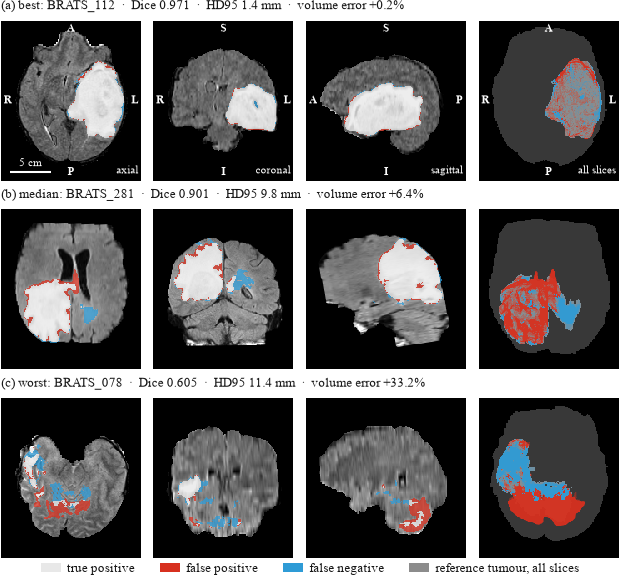

In [31]:
REF_PROJ = "#8C8C8C"           # reference tumour in the projection column: between brain grey and true-positive grey
FRAME = {"axial": (192, 168), "coronal": (192, 168), "sagittal": (192, 192)}   # (rows, columns) in voxels = mm


fig = plt.figure(figsize=figsize("full", aspect=0.92))
rows_fig = fig.subfigures(4, 1, hspace=0.0, height_ratios=[1, 1, 1, 0.07])
for r, (name, cid) in enumerate(picked.items()):
    ref, _ = test_refs[cid]
    pred = final_pred[cid]
    flair = flair_full(cid)
    brain = flair != 0
    brain_centre = np.round(np.argwhere(brain).mean(axis=0)).astype(int)
    cut = np.round(np.argwhere(ref | pred).mean(axis=0)).astype(int)
    lo, hi = np.percentile(flair[brain], [0.5, 99.5])
    m = test_pp.loc[cid]
    sub = rows_fig[r]
    axes = sub.subplots(1, 4, width_ratios=[FRAME["axial"][1], FRAME["coronal"][1], FRAME["sagittal"][1], FRAME["axial"][1]])
    sub.suptitle(f"({'abc'[r]}) {name}: {cid}  ·  Dice {m['dice']:.3f}  ·  HD95 {m['hd95_mm']:.1f} mm  ·  "
                 f"volume error {m['vol_err_pct']:+.1f}%".replace("-", "−"), x=0.01, ha="left", fontsize=LABEL_PT - 1)
    for k, which in enumerate(PLANES):
        idx = plane_index(cut, which)
        rc = display_centre(brain_centre, which, flair.shape)
        cropped = [frame(plane(v, which, idx), rc, FRAME[which]) for v in (flair, ref, pred)]
        ax = axes[k]
        show_plane(ax, cropped[0], window=(lo, hi), letters=EDGE_LETTERS[which] if r == 0 else None)
        error_overlay(ax, cropped[1], cropped[2])
        if r == 0:                                                   # plane name inside the panel keeps tiles equal
            ax.text(0.98, 0.03, which, transform=ax.transAxes, ha="right", va="bottom", fontsize=TICK_PT - 1, color="white")
    # (d) all slices projected along the superior-inferior axis
    fp = (pred & ~ref.astype(bool)).sum(axis=2).astype(float)
    fn = (ref.astype(bool) & ~pred.astype(bool)).sum(axis=2).astype(float)
    silhouette = brain.any(axis=2).astype(float)
    rc = display_centre(brain_centre, "axial", flair.shape)
    sil = frame(silhouette[::-1, :].T, rc, FRAME["axial"])
    fpp, fnp = frame(fp[::-1, :].T, rc, FRAME["axial"]), frame(fn[::-1, :].T, rc, FRAME["axial"])
    ax = axes[3]
    refp = frame(ref.astype(bool).any(axis=2)[::-1, :].T.astype(float), rc, FRAME["axial"])
    ax.imshow(np.where(sil > 0, 0.22, 0.0), cmap="gray", vmin=0, vmax=1, origin="lower", interpolation="nearest")
    tumour = np.zeros(refp.shape + (4,))                              # reference tumour in any slice
    tumour[refp > 0] = (*matplotlib.colors.to_rgb(REF_PROJ), 1.0)
    ax.imshow(tumour, origin="lower", interpolation="nearest")
    total = fpp + fnp
    rgba = np.zeros(total.shape + (4,))
    rgba[..., :3] = np.where((fpp >= fnp)[..., None], matplotlib.colors.to_rgb(ERR["FP"]), matplotlib.colors.to_rgb(ERR["FN"]))
    rgba[..., 3] = np.clip(total / 6, 0, 1) * 0.95                  # 6 or more error voxels in a column: opaque
    ax.imshow(rgba, origin="lower", interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    if r == 0:
        for (tx, ty, letter, ha, va) in [(0.02, 0.5, "R", "left", "center"), (0.98, 0.5, "L", "right", "center"),
                                         (0.5, 0.98, "A", "center", "top"), (0.5, 0.02, "P", "center", "bottom")]:
            ax.text(tx, ty, letter, transform=ax.transAxes, ha=ha, va=va, fontsize=TICK_PT - 1, color="white",
                    fontweight="bold")
        ax.text(0.98, 0.03, "all slices", transform=ax.transAxes, ha="right", va="bottom", fontsize=TICK_PT - 1,
                color="white")
        # 5 cm scale bar in the first panel
        axes[0].plot([10, 60], [10, 10], color="white", lw=1.5, solid_capstyle="butt")
        axes[0].text(35, 14, "5 cm", color="white", fontsize=TICK_PT - 1, ha="center", va="bottom")
rows_fig[3].legend(handles=error_handles() + [matplotlib.patches.Patch(facecolor=REF_PROJ, edgecolor="none",
                   label="reference tumour, all slices")], loc="center", ncol=4, frameon=False)
save_and_show(fig, "G_errors", width="full")
plt.close(fig)

### G.2 Where the errors are: boundary, small structures, patch context
Three measurements over all test cases tie the errors to their causes:
- **boundary**: the share of false-positive and false-negative voxels lying within 2 mm of the reference surface;
  errors there are disagreements about where the tumour edge is, not missed or invented lesions;
- **small structures**: reference components smaller than 1 mL, and how many of them the prediction touches;
- **far false positives**: predicted components that do not touch the reference at all, by size.

In [32]:
from scipy import ndimage
from helpers.inference import CONNECTIVITY

rows, small_ref, far_fp = [], [], []
for cid in test_ids:
    ref, spacing = test_refs[cid]
    pred = full_mask(test_masks[cid], cid, CONFIG, MIN_VOXELS).astype(bool)
    ref_b = ref.astype(bool)
    surface = ref_b & ~ndimage.binary_erosion(ref_b, structure=CONNECTIVITY)
    dist = ndimage.distance_transform_edt(~surface, sampling=spacing)
    err = pred ^ ref_b
    rows.append({"case_id": cid, "error voxels": int(err.sum()),
                 "share within 2 mm of reference surface": float((dist[err] <= 2).mean()) if err.any() else np.nan})
    labels, sizes = components(ref_b)
    for j, size in enumerate(sizes, start=1):
        if size < 1000:
            small_ref.append({"case_id": cid, "size (mL)": size / 1000, "detected": bool(pred[labels == j].any())})
    labels, sizes = components(pred)
    for j, size in enumerate(sizes, start=1):
        if not ref_b[labels == j].any():
            far_fp.append({"case_id": cid, "size (mL)": size / 1000})
boundary = pd.DataFrame(rows).set_index("case_id")
small_ref, far_fp = pd.DataFrame(small_ref), pd.DataFrame(far_fp, columns=["case_id", "size (mL)"])
print(f"share of error voxels within 2 mm of the reference surface: median {boundary.iloc[:, 1].median():.2f} "
      f"(IQR {boundary.iloc[:, 1].quantile(0.25):.2f}–{boundary.iloc[:, 1].quantile(0.75):.2f}) over {len(boundary)} cases")
if len(small_ref):
    print(f"reference components < 1 mL: {len(small_ref)} in {small_ref['case_id'].nunique()} cases; "
          f"detected {small_ref['detected'].sum()} ({small_ref['detected'].mean():.0%})")
print(f"predicted components not touching the reference (after postprocessing): {len(far_fp)} in "
      f"{far_fp['case_id'].nunique()} cases, total {far_fp['size (mL)'].sum():.1f} mL, median size "
      f"{far_fp['size (mL)'].median() if len(far_fp) else float('nan'):.2f} mL")
display(boundary.loc[list(picked.values())].assign(case=list(picked.keys())))

# the three pictured cases: reference lesions missed entirely, and where the false positives lie
def describe(cid, name):
    ref_b = test_refs[cid][0].astype(bool)
    pred_b = full_mask(test_masks[cid], cid, CONFIG, MIN_VOXELS).astype(bool)
    labels, sizes = components(ref_b)
    main_centre = np.argwhere(labels == np.argmax(sizes) + 1).mean(axis=0)
    missed = [(size / 1000, np.linalg.norm(np.argwhere(labels == j).mean(axis=0) - main_centre))
              for j, size in enumerate(sizes, start=1) if size >= 1000 and not (pred_b & (labels == j)).any()]
    plabels, _ = components(pred_b)
    fp = pred_b & ~ref_b
    touching = np.isin(plabels, np.unique(plabels[pred_b & ref_b]))      # components that contain true positive voxels
    print(f"{name} {cid}: {len(missed)} reference lesion(s) of at least 1 mL missed entirely"
          + "".join(f"; {v:.1f} mL at {d:.0f} mm from the main tumour's centre" for v, d in missed)
          + f" | false positives {fp.sum() / 1000:.1f} mL, {(fp & touching).sum() / max(fp.sum(), 1):.0%} of them in "
            f"components connected to true tumour")


for name, cid in picked.items():
    describe(cid, name)
describe(worse_hd.index[0], "largest HD95 increase from postprocessing (F.3):")

share of error voxels within 2 mm of the reference surface: median 0.92 (IQR 0.82–0.97) over 73 cases
reference components < 1 mL: 480 in 61 cases; detected 44 (9%)
predicted components not touching the reference (after postprocessing): 1 in 1 cases, total 8.9 mL, median size 8.95 mL


,error voxels,share within 2 mm of reference surface,case
case_id,,,
BRATS_112,9897,0.979085,best
BRATS_281,35397,0.899059,median
BRATS_078,78293,0.466836,worst


best BRATS_112: 0 reference lesion(s) of at least 1 mL missed entirely | false positives 5.2 mL, 100% of them in components connected to true tumour


median BRATS_281: 0 reference lesion(s) of at least 1 mL missed entirely | false positives 23.3 mL, 100% of them in components connected to true tumour


worst BRATS_078: 0 reference lesion(s) of at least 1 mL missed entirely | false positives 53.3 mL, 100% of them in components connected to true tumour


largest HD95 increase from postprocessing (F.3): BRATS_253: 3 reference lesion(s) of at least 1 mL missed entirely; 1.2 mL at 82 mm from the main tumour's centre; 1.6 mL at 71 mm from the main tumour's centre; 1.8 mL at 60 mm from the main tumour's centre | false positives 3.1 mL, 100% of them in components connected to true tumour


**What the errors are.** Most errors are boundary disagreements: across the 73 test cases the median share of error
voxels within 2 mm of the reference surface is 92%, and in the best case (BRATS_112) the errors form a one-voxel rim
around a correct tumour, where oedema fades into normal tissue and the reference itself is least certain. In the
median case (BRATS_281) every false positive is attached to the tumour (23.3 mL along its border), and the 12.1 mL it
misses lies largely where the tumour extends across the midline (blue in the projection), a part the network
under-calls rather than a separate lesion. Small structures are the second failure: of 480 reference components
smaller than 1 mL, only 9% are touched by the prediction, and the postprocessing rule turned partly detected satellite
lesions into missed ones (BRATS_253, F.3). The worst case (BRATS_078) shows a patch-context failure. Its coronal and
sagittal planes are visibly smeared, consistent with thick original slices, and the prediction grows from the true
lesion into the posterior fossa as one connected region: all 53.3 mL of its false positives are attached to true
tumour, while it misses 25.0 mL of the lesion itself. A 64 mm patch sees only local texture; where that texture looks
abnormal for other reasons, nothing in the patch tells the network where the tumour ends.

### G.3 One metric is not enough

In [33]:
three = test_pp.loc[list(picked.values()), ["dice", "iou", "sensitivity", "hd95_mm", "ref_ml", "pred_ml",
                                             "vol_err_ml", "vol_err_pct", "fp_ml", "fn_ml"]]
three.insert(0, "case", list(picked.keys()))
display(style_table(three, precision=2, caption="Best, median and worst test cases by Dice"))
three.to_csv(TABLE_DIR / "three_cases.csv")
rho = test_pp[["dice", "hd95_mm", "abs_vol_err_pct"]].corr(method="spearman")
display(rho.round(2))

,case,dice,iou,sensitivity,hd95_mm,ref_ml,pred_ml,vol_err_ml,vol_err_pct,fp_ml,fn_ml
case_id,,,,,,,,,,,
BRATS_112,best,0.97,0.94,0.97,1.41,169.19,169.59,0.41,0.24,5.15,4.74
BRATS_281,median,0.90,0.82,0.93,9.80,173.93,185.11,11.18,6.43,23.29,12.11
BRATS_078,worst,0.61,0.43,0.71,11.40,85.08,113.31,28.23,33.18,53.26,25.03


,dice,hd95_mm,abs_vol_err_pct
dice,1.00,-0.74,-0.73
hd95_mm,-0.74,1.00,0.52
abs_vol_err_pct,-0.73,0.52,1.00


**One number per case is not enough.** The cases rank differently on each metric. The median case (Dice 0.901) has a
smaller HD95 than the worst case (9.8 vs 11.4 mm) by only 1.6 mm, although its Dice is 0.30 higher: HD95 reports the
farthest 5% of boundary errors, and both cases have errors about a centimetre from the reference surface. The worst
case's volume error (+33.2%) is five times the median case's (+6.4%), but volume error hides compensating mistakes: a
case can miss 25 mL and add 25 mL and still score 0%. And BRATS_253 (F.3) has a Dice of 0.903, near the median, with
an HD95 of 56.9 mm, seven times the test mean of 7.7 mm, because three small missed lesions lie 6 to 8 cm away: Dice
barely notices a few millilitres, HD95 measures how far away they are. Over all 73 test cases Dice correlates with
HD95 and with absolute volume error only moderately (Spearman −0.74 and −0.73), and HD95 with volume error weakly
(0.52). Overlap, boundary distance and volume answer different questions (how much agrees, how far the worst errors
reach, how wrong a volume measurement would be), so a report needs all three.

### G.4 Limitations
- **Small training budget.** Each run saw 12,000 patches (3,000 iterations) on one laptop GPU; validation Dice was
  still creeping up at the end, so the absolute numbers understate what this architecture can reach.
- **No external-site validation.** All cases come from one curated benchmark (BraTS 2016/2017 via MSD), with shared
  preprocessing (skull stripping, co-registration, resampling to 1 mm). Performance on raw scans from another
  hospital, scanner or protocol is untested and probably lower.
- **Reference, not truth.** The label is one research segmentation per case; raters disagree most at the oedema
  edge, exactly where most of our errors lie, so part of the "error" is label noise.
- **Few seeds and one split.** The sampler comparison rests on the seeds trained here and the supplied split;
  confidence intervals cover case-sampling noise, not variation from re-splitting.
- **Whole tumour only.** The sub-regions (enhancing tumour, necrosis) that matter clinically were not modelled, and
  the postprocessing rule was tuned on Dice alone, which removes small true lesions.

## Bonus 1. Missing-modality stress test
Without retraining, each MRI channel in turn is replaced by zeros at test time; everything else (model, overlap,
threshold, postprocessing) is the final pipeline. After z-scoring, 0 is the brain's mean intensity of that
channel, so the channel becomes a flat, contrast-free image inside the brain.

In [34]:
mm_rows, mm_scores = [], {}
for c, name in [(None, "all four channels")] + list(enumerate(CHANNELS)):
    if c is None:
        df = test_pp
    else:
        masks_c, _, _ = predict_split(final_model, test_ids, CONFIG, DEVICE, zero_channel=c)
        df = score_split(masks_c, test_refs, CONFIG, min_voxels=MIN_VOXELS)
    mm_scores[name] = df
    row = {"input": name if c is None else f"{name} zeroed", "Dice mean": df["dice"].mean(),
           "Dice median": df["dice"].median(), "HD95 median (mm)": df["hd95_mm"].median(),
           "|volume error| median (%)": df["abs_vol_err_pct"].median(), "empty predictions": int(df["empty_pred"].sum())}
    if c is not None:
        d, lo, hi = paired_bootstrap_diff(df["dice"], test_pp["dice"])
        row["ΔDice vs all four [95% CI]"] = f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]"
    mm_rows.append(row)
mm_table = pd.DataFrame(mm_rows).set_index("input")
display(style_table(mm_table, precision=3, caption="Test split, 73 cases: one channel replaced by zeros"))
mm_table.to_csv(TABLE_DIR / "missing_modality.csv")

,Dice mean,Dice median,HD95 median (mm),|volume error| median (%),empty predictions,ΔDice vs all four [95% CI]
input,,,,,,
all four channels,0.885,0.901,4.899,10.135,0,–
FLAIR zeroed,0.087,0.000,32.156,100.000,48,"-0.798 [-0.830, -0.762]"
T1 zeroed,0.823,0.858,14.457,19.607,0,"-0.062 [-0.084, -0.042]"
T1ce zeroed,0.857,0.883,5.831,17.109,0,"-0.028 [-0.041, -0.018]"
T2 zeroed,0.789,0.860,7.550,19.384,2,"-0.096 [-0.140, -0.057]"


PASS X1_missing_modality: 0 errors, 5 warnings, 0 taste notes -> figures/_preview/X1_missing_modality.png
  [warn] annotation: 'mean 0.885' sits outside its axes
  [warn] annotation: 'mean 0.087, 48 of 73 empty' sits outside its axes
  [warn] annotation: 'mean 0.823' sits outside its axes
  [warn] annotation: ... 2 more (see _audit/X1_missing_modality.json)


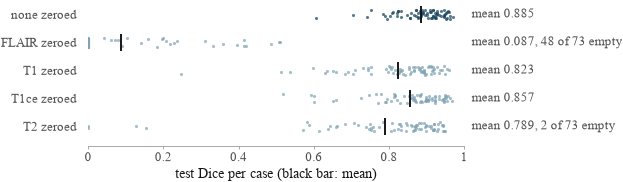

In [35]:
fig, ax = plt.subplots(figsize=figsize("full", aspect=0.3))
names = ["all four channels"] + CHANNELS
for k, name in enumerate(names):
    df = mm_scores[name]
    v = df["dice"].to_numpy()
    color = method_style(FINAL_SAMPLER)["color"] if k == 0 else SLATE
    ax.scatter(v, k + np.random.default_rng(k).uniform(-0.17, 0.17, len(v)), s=5, color=color, alpha=0.7, linewidths=0)
    ax.plot([v.mean()] * 2, [k - 0.3, k + 0.3], color=INK, lw=1.4, solid_capstyle="butt")
    note = f"mean {v.mean():.3f}" + (f", {int(df['empty_pred'].sum())} of {len(df)} empty" if df["empty_pred"].sum() else "")
    ax.text(1.02, k, note, transform=ax.get_yaxis_transform(), va="center", ha="left", fontsize=TICK_PT, color=MUTED)
ax.set_yticks(range(len(names)), ["none zeroed"] + [f"{n} zeroed" for n in CHANNELS])
ax.set_ylim(len(names) - 0.5, -0.5)
ax.set_xlim(0, 1)
ax.set_xlabel("test Dice per case (black bar: mean)")
finish(ax, categorical="y", snap=False)
save_and_show(fig, "X1_missing_modality", width="column")
plt.close(fig)

**Most influential channel.** FLAIR. Zeroing it collapses the model (mean Dice 0.087; 48 of 73 predictions are
empty), whereas zeroing T2, T1 or T1ce costs 0.096, 0.062 and 0.028 Dice. Whole tumour is mostly oedema, and
oedema is what FLAIR shows best (bright, with cerebrospinal fluid suppressed), with T2 a weaker second view of the
same fluid; the network has learned to rely on FLAIR almost entirely, and the other channels refine the boundary but
cannot replace it.

**Why zeroing is an imperfect simulation.** After z-scoring, 0 is the brain's mean intensity, so a zeroed channel is
a flat grey image with no contrast at all, an input the network never saw in training. A genuinely missing
acquisition is different: the scan is simply absent (the pipeline would have to fill something in), or a different
sequence takes its place, or it is present but degraded by motion or a different protocol. Zeroing measures how
much the trained weights depend on a channel, not how a real missing-sequence workflow would perform, and it can
exaggerate the damage because the flat channel also shifts the network's internal normalisation statistics.

**Training for missing modalities.** Randomly drop channels during training (modality dropout: replace each
channel with zeros, or with a learned "missing" value, with a fixed probability, and add an availability mask as extra
input), so the network learns not to depend on any single sequence. Architectures that encode each modality
separately and fuse them with an order-free operation (for example the mean and variance across available
modalities, as in HeMIS) handle any subset by design; distillation from a full-modality teacher or synthesising the
missing sequence are further options.

## Bonus 2. Sliding-window seam test
The same final model predicts with 0%, 25% and 50% window overlap (Gaussian blending throughout). The overlap
setting is judged on validation; the test split is evaluated once per setting only to report the result. To see
the seams, the probability maps with 0% and 50% overlap are compared as a function of the distance of each voxel to
the nearest internal border of the 0%-overlap window grid.

In [36]:
seam_rows, seam_probs = [], {}
for overlap in [0.0, 0.25, 0.5]:
    for split_name, cids, refs in [("validation", val_ids, val_refs), ("test", test_ids, test_refs)]:
        masks_o, secs, probs = predict_split(final_model, cids, CONFIG, DEVICE, overlap=overlap,
                                             keep_prob=val_ids if split_name == "validation" and overlap in (0.0, 0.5) else ())
        df = score_split(masks_o, refs, CONFIG, min_voxels=MIN_VOXELS)
        stride = int(round(P * (1 - overlap)))
        n_win = np.mean([np.prod([len(window_starts(s, P, stride)) for s in metas[c]["cache_shape"]]) for c in cids])
        seam_rows.append({"overlap": f"{overlap:.0%}", "split": split_name, "windows per case": n_win,
                          "seconds per case": np.mean(list(secs.values())), "Dice mean": df["dice"].mean(),
                          "HD95 median (mm)": df["hd95_mm"].median(),
                          "|volume error| median (%)": df["abs_vol_err_pct"].median()})
        if probs:
            seam_probs[overlap] = probs
seam_table = pd.DataFrame(seam_rows).set_index(["split", "overlap"]).sort_index()
display(style_table(seam_table, precision=3, caption="Window overlap: run time and metrics (final model, postprocessed)"))
seam_table.to_csv(TABLE_DIR / "seams.csv")

In [37]:
def border_distance(shape, P, stride):
    """Per voxel: distance (voxels) to the nearest internal window border of a grid with this stride."""
    out = np.full(shape, np.inf)
    for axis, s in enumerate(shape):
        starts = window_starts(s, P, stride)
        borders = sorted({b for a in starts for b in (a, a + P)} - {0, s})
        if not borders:
            continue
        coord = np.arange(s)[:, None] + 0.5
        d = np.min(np.abs(coord - np.array(borders)[None, :]), axis=1)
        out = np.minimum(out, d.reshape([-1 if i == axis else 1 for i in range(3)]))
    return out


# Only voxels where at least one of the two maps is not confidently background (p >= 0.05) are compared: elsewhere
# both maps are ~0 and any difference is invisible after thresholding.
rows = []
for cid in val_ids:
    p0, p50 = seam_probs[0.0][cid], seam_probs[0.5][cid]
    active = np.maximum(p0, p50) >= 0.05
    dist = np.floor(border_distance(p0.shape, P, P)[active]).clip(0, P // 2 - 1)
    rows.append(pd.DataFrame({"distance": dist, "absdiff": np.abs(p0 - p50)[active],
                              "flip": (p0[active] >= 0.5) != (p50[active] >= 0.5)}))
seam_curve = pd.concat(rows).groupby("distance").agg(mean_absdiff=("absdiff", "mean"), flip_share=("flip", "mean"),
                                                     voxels=("flip", "size"))
display(seam_curve.round(4).T)
near, far = seam_curve.loc[:3], seam_curve.loc[16:]
print(f"label flips between 0% and 50% overlap: {np.average(near['flip_share'], weights=near['voxels']):.1%} of compared "
      f"voxels within 4 voxels of a window border vs {np.average(far['flip_share'], weights=far['voxels']):.1%} "
      f"16 or more voxels away")

distance,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,22.0,23.0,24.0,25.0,26.0,27.0,28.0,29.0,30.0,31.0
mean_absdiff,1.304000e-01,1.188000e-01,1.097000e-01,0.1003,0.0942,0.0888,0.0853,0.0829,0.0795,0.0752,...,0.0077,0.0060,0.0049,0.0038,0.0039,0.0031,0.0024,0.0018,0.0012,0.0009
flip_share,1.217000e-01,1.114000e-01,1.027000e-01,0.0933,0.0870,0.0812,0.0785,0.0773,0.0740,0.0699,...,0.0040,0.0037,0.0018,0.0021,0.0009,0.0014,0.0000,0.0016,0.0025,0.0000
voxels,1.429686e+06,1.248159e+06,1.086417e+06,923342.0000,794594.0000,677780.0000,572404.0000,510387.0000,444826.0000,386048.0000,...,24534.0000,17157.0000,11005.0000,7277.0000,3472.0000,2114.0000,1190.0000,638.0000,397.0000,260.0000


label flips between 0% and 50% overlap: 10.9% of compared voxels within 4 voxels of a window border vs 1.7% 16 or more voxels away


PASS X2_seams: 0 errors, 0 warnings, 6 taste notes -> figures/_preview/X2_seams.png
  [taste] crowded: '1.5' and 'distance to nearest window border (voxel' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] crowded: '1.5' and 'labels that change (%)' (different panels) nearly touch; add wspace/hspace or use fewer ticks
  [taste] contrast: 'R' is too light to read; use text_color()
  [taste] contrast: 'L' is too light to read; use text_color()
  [taste] contrast: 'A' is too light to read; use text_color()
  [taste] contrast: ... 1 more (see _audit/X2_seams.json)


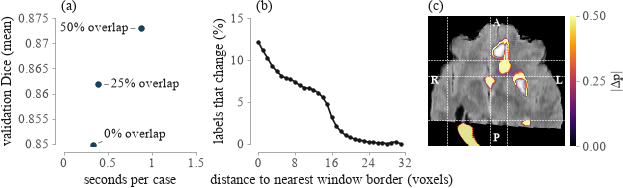

In [38]:
ex = val_ids[0]
p0, p50 = seam_probs[0.0][ex], seam_probs[0.5][ex]
diff = np.abs(p0 - p50)
z = int(np.argmax(diff.sum(axis=(0, 1))))
flair_ex = np.asarray(load_cached(ex, CACHE_DIR, with_label=False)[0][0], dtype=np.float32)

fig, axes = plt.subplots(1, 3, figsize=figsize("full", aspect=0.31), width_ratios=[1, 1.1, 1.05])
ax = axes[0]
val_rows = seam_table.loc["validation"]
ax.plot(val_rows["seconds per case"], val_rows["Dice mean"], color=method_style(FINAL_SAMPLER)["color"], marker="o", ms=4, lw=0)
ax.set_xlabel("seconds per case")
ax.set_ylabel("validation Dice (mean)")
ax.set_title("(a)", loc="left")
ax.update_datalim([[0, val_rows["Dice mean"].min()], [1.25 * val_rows["seconds per case"].max(), val_rows["Dice mean"].max()]])
finish(ax)                                                          # axis from 0 s, with room for the labels
label_points(ax, [((r["seconds per case"], r["Dice mean"]), f"{ov} overlap") for ov, r in val_rows.iterrows()])
ax = axes[1]
ax.plot(seam_curve.index, 100 * seam_curve["flip_share"], color=INK, marker="o", ms=2.5)
ax.set_xlabel("distance to nearest window border (voxels)")
ax.set_ylabel("labels that change (%)")
ax.set_title("(b)", loc="left")
ax.set_xticks([0, 8, 16, 24, 32])
finish(ax)
ax.set_xticks([0, 8, 16, 24, 32])
ax.set_xlim(-0.5, 32.5)
ax.spines["bottom"].set_bounds(0, 32)
ax = axes[2]
view2 = crop_box(flair_ex != 0, margin=2)
show_plane(ax, plane(flair_ex[view2], "axial", z - view2[2].start), letters=EDGE_LETTERS["axial"])
d2 = plane(diff[view2], "axial", z - view2[2].start)
rgba = matplotlib.colormaps["inferno"](np.clip(d2 / 0.5, 0, 1))
rgba[..., 3] = np.clip(d2 / 0.25, 0, 1) * 0.9                    # transparent where the two maps agree
ax.imshow(rgba, origin="lower", interpolation="nearest")
nx, ny = flair_ex.shape[0], flair_ex.shape[1]
# window borders of the 0%-overlap grid (display columns run right -> left, so x borders are mirrored)
for b_ in sorted({b for a_ in window_starts(nx, P, P) for b in (a_, a_ + P)} - {0, nx}):
    ax.axvline(view2[0].stop - b_ - 0.5, color="white", lw=0.5, ls=(0, (2, 2)))
for b_ in sorted({b for a_ in window_starts(ny, P, P) for b in (a_, a_ + P)} - {0, ny}):
    ax.axhline(b_ - view2[1].start - 0.5, color="white", lw=0.5, ls=(0, (2, 2)))
ax.set_title("(c)", loc="left")
sm = matplotlib.cm.ScalarMappable(cmap="inferno", norm=matplotlib.colors.Normalize(0, 0.5))
cb = fig.colorbar(sm, ax=ax, fraction=0.05, pad=0.03, ticks=[0, 0.25, 0.5])
cb.set_label("|Δp|", fontsize=TICK_PT)
cb.ax.tick_params(labelsize=TICK_PT)
cb.outline.set_visible(False)
save_and_show(fig, "X2_seams", width="full")
plt.close(fig)

**What overlap buys.** Overlap costs time and buys agreement at window borders. On validation, 0% overlap needs
about 26 windows per case, 25% about 35 and 50% about 77, and Dice rises from 0.850 to 0.862 to 0.873, while the run
time grows from 0.33 to 0.88 s per case. Panel (b) shows where the gain comes from: when the 0% and 50% predictions are
compared, labels change for 10.9% of the compared voxels within four voxels of a window border, against 1.7% sixteen
or more voxels away. Near a border the network sees the tumour cut off by the patch edge and its zero padding; with
overlap, every border voxel is also seen near the centre of another window, and the Gaussian weights let that more
informed prediction dominate. Overlap helps most when tumours are large relative to the patch (as here: a 64 mm
patch, tumours of 5 to 6 cm) and matters little for structures that fit well inside one window.

**Why choosing the overlap on test labels would bias the result.** If we tried a few overlaps (or blendings,
thresholds, rules) and kept the one with the best test Dice, the reported test score would be the maximum of
a few noisy estimates and would be optimistically biased: part of the "improvement" would be chance agreement with
these 73 cases, which would not carry over to new patients. The test set would then have become a second
validation set, and no unbiased estimate would remain. The overlap must be fixed on validation (here 50%, the best
on validation); the test rows above only report the consequence.